# Set Covering Problem — Constructive Heuristics and Iterative Improvement
### Exercise 1.1 / 1.2 — CH1, CH2, CH3, redundancy elimination, FI and BI local search

This notebook builds three constructive heuristics (CH1 random, CH2 greedy cost/gain, CH3 regret), applies redundancy elimination (RE), and then implements two iterative improvement algorithms — first-improvement (FI) and best-improvement (BI) — for the SCP.

### The notebook covers:
1. Instance reading, incremental solution state and best-known solutions (BKS).
2. Constructive heuristics CH1, CH2, CH3 and RE (CH1+RE is RE applied to the CH1 solution).
3. Two local-search neighborhoods: **1-1 swap + RE** and **remove one set + greedy repair + RE**; FI and BI for each.
4. 16 experiments per instance (4 starting solutions × FI/BI × 2 neighborhoods). The 8 required ones use the swap neighborhood.
5. Results: average % deviation from BKS, total computation time, fraction of instances improved by local search, plots and interpretation.
6. Simulated annealing (SA) with N1, N2 and a mixed N1/N2 neighbourhood: calibrated cooling schedule, parameter tuning (factorial design) and final comparison.


## 1. Imports and configuration

`DATA_DIR` is relative to the notebook's current working directory. The data is in the `SCP-Instances/`, in the same directory.

In [9]:
import heapq
import random
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.container import BarContainer

from scipy.stats import wilcoxon


DATA_DIR = Path("SCP-Instances")
SEED = 42


## 2. OR-Library SCP format

Each instance has the form

```text
m n
c_1 ... c_n
k_1 <k_1 column indices>
...
k_m <k_m column indices>
```

Here `m` is the number of elements (rows) and `n` is the number of available sets (columns). The file uses **1-based** column indices; the implementation converts them to **0-based** indices.

In [10]:
def read_scp_instance(filepath):
    """Read one SCP instance in OR-Library format.

    Format:
        m n
        c_1 ... c_n
        k_1 <k_1 column indices (1-based)>
        ...
        k_m <k_m column indices (1-based)>

    Returns dict containing m, n, costs array, rows list, and cols list.
    """
    filepath = Path(filepath)
    tokens = filepath.read_text().split()
    if len(tokens) < 2:
        raise ValueError(f"{filepath}: file is too short to contain m and n")

    values = [int(x) for x in tokens]
    idx = 0
    m, n = values[idx], values[idx + 1]
    idx += 2

    if m <= 0 or n <= 0:
        raise ValueError(f"{filepath}: invalid dimensions m={m}, n={n}")

    costs = np.asarray(values[idx : idx + n], dtype=float)
    idx += n

    rows = []
    for e in range(m):
        k = values[idx]
        idx += 1
        covering = [c - 1 for c in values[idx : idx + k]]  # Convert to 0-based
        idx += k
        rows.append(covering)

    cols = [[] for _ in range(n)]
    for e, covering in enumerate(rows):
        for j in covering:
            cols[j].append(e)

    return {"m": m, "n": n, "costs": costs, "rows": rows, "cols": cols}


## 3. Incremental solution state

The central idea is to avoid repeatedly recomputing coverage from scratch. For a partial solution we maintain:

| State | Meaning | Update/query | 
|---|---|---|
| `chosen[j]` | set `j` is selected | O(1) lookup | 
| `cover_count[e]` | number of selected sets covering element `e` | updated only when a set is added/removed | 
| `uncovered` + `_pos` | current uncovered elements | O(1) swap-remove/append | 
| `gain[j]` | number of currently uncovered elements that set `j` would cover | maintained incrementally | 
| `solution_cost` | total cost of selected sets | O(1) update | 

The key candidate condition is `gain[j] > 0`. Therefore a redundant set (`gain == 0`) is never selected during construction.

When an element changes from uncovered to covered, every set containing that element loses one unit of gain. During RE, the reverse update restores that gain if the element becomes uncovered again.

In [11]:
class SCPInstance:
    """Maintains incremental solution state for Set Covering Problem.

    State variables maintained in O(1) / O(k):
    - chosen: boolean mask of selected sets
    - cover_count: number of selected sets covering element e
    - gain: number of uncovered elements covered by set j
    - uncovered & _pos: O(1) list for fast sampling and state maintenance
    - solution_cost: total cost of currently chosen sets
    """

    def __init__(self, data, name=None):
        self.name = name
        self.m, self.n = data["m"], data["n"]
        self.costs = np.asarray(data["costs"], dtype=float)
        self.rows = data["rows"] # element -> covering sets (lists)
        self.cols = data["cols"]  # set -> covered elements (lists)
        self.rows_np = [np.asarray(r, dtype=np.int64) for r in self.rows]
        self.cols_np = [np.asarray(c, dtype=np.int64) for c in self.cols]
        self.col_size = np.asarray([len(c) for c in self.cols], dtype=np.int64)
        self.reset()

    # ---------------------------------------------------------------- state
    def reset(self):
        self.chosen = np.zeros(self.n, dtype=bool)
        self.cover_count = np.zeros(self.m, dtype=np.int64)
        self.gain = self.col_size.copy()    # nothing covered yet -> gain = column size
        self.uncovered = list(range(self.m))  # list of uncovered elements
        self._pos = np.arange(self.m, dtype=np.int64) # position of each element inside `uncovered`
        self.solution_cost = 0.0

    def snapshot(self):
        """Return a deep copy snapshot of current state."""
        return {
            "chosen": self.chosen.copy(),
            "cover_count": self.cover_count.copy(),
            "gain": self.gain.copy(),
            "uncovered": self.uncovered.copy(),
            "_pos": self._pos.copy(),
            "solution_cost": float(self.solution_cost),
        }

    def restore(self, state):
        """Restore instance state from a snapshot."""
        self.chosen = state["chosen"].copy()
        self.cover_count = state["cover_count"].copy()
        self.gain = state["gain"].copy()
        self.uncovered = state["uncovered"].copy()
        self._pos = state["_pos"].copy()
        self.solution_cost = float(state["solution_cost"])

    def is_complete_cover(self):
        return len(self.uncovered) == 0

    def solution_sets(self):
        return np.flatnonzero(self.chosen).tolist()
    
    # ------------------------------------------------ O(1) uncovered-list ops
    def _mark_covered(self, e):
        pos = int(self._pos[e])
        last = self.uncovered.pop()
        if last != e:
            self.uncovered[pos] = last
            self._pos[last] = pos
        self.gain[self.rows_np[e]] -= 1

    def _mark_uncovered(self, e):
        self._pos[e] = len(self.uncovered)
        self.uncovered.append(e)
        self.gain[self.rows_np[e]] += 1

    # ------------------------------------------------------------ mutations
    def add_set(self, j):
        j = int(j)
        if self.chosen[j]:
            return 0
        self.chosen[j] = True
        self.solution_cost += self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] += 1
        newly_covered = els[self.cover_count[els] == 1]
        for e in newly_covered:
            self._mark_covered(int(e))
        return len(newly_covered)

    def remove_set(self, j):
        j = int(j)
        if not self.chosen[j]:
            return 0
        self.chosen[j] = False
        self.solution_cost -= self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] -= 1
        newly_uncovered = els[self.cover_count[els] == 0]
        for e in newly_uncovered:
            self._mark_uncovered(int(e))
        return len(newly_uncovered)
    
    # -------------------------------------------------------------- queries
    def is_removable(self, j):
        """A set is removable if all its covered elements are covered by >= 2 sets."""
        return bool(np.all(self.cover_count[self.cols_np[int(j)]] > 1))
    
    # -------------------------------------------------------- verification
    def check_solution(self):
        """Verify feasibility and cost correctness."""
        covered = np.zeros(self.m, dtype=bool)
        for j in np.flatnonzero(self.chosen):
            covered[self.cols_np[j]] = True
        if not covered.all():
            raise AssertionError(f"{self.name}: incomplete set cover")
        if not np.isclose(self.solution_cost, self.costs[self.chosen].sum()):
            raise AssertionError(f"{self.name}: cost mismatch")

## 4. Instance loading and best-known solutions

The filename convention used here maps names such as `scp42.txt` to instance label `4.2`, and `scpA3.txt` to `A.3`. Duplicate labels are rejected rather than silently overwritten.

The Best Known Solution (BKS) dictionary is kept separate from the heuristic code so that the percentage-deviation calculation is easy to audit.

In [12]:
FNAME_RE = re.compile(r"scp([A-Za-z]|\d)(\d+)", re.IGNORECASE)

def label_from_filename(path):
    match = FNAME_RE.search(Path(path).name)
    if not match:
        return None
    group, num = match.groups()
    return f"{group.upper()}.{num}"

def sort_key(label):
    cls, num = label.split(".")
    return (cls, int(num))

def load_all_instances(data_dir):
    data_dir = Path(data_dir)
    if not data_dir.exists():
        return {}

    instances = {}
    for path in sorted(data_dir.iterdir()):
        if not path.is_file():
            continue
        label = label_from_filename(path)
        if label is None:
            continue
        if label in instances:
            raise ValueError(f"Duplicate instance label {label!r}: multiple files match it")
        instances[label] = SCPInstance(read_scp_instance(path), name=label)

    return dict(sorted(instances.items(), key=lambda kv: sort_key(kv[0])))

BKS = {
    "4.2": 512, "4.3": 516, "4.4": 494, "4.5": 512,
    "4.6": 560, "4.7": 430, "4.8": 492, "4.9": 641, 
    "5.1": 253, "5.2": 302, "5.3": 226, "5.4": 242, "5.5": 211,
    "5.6": 213, "5.7": 293, "5.8": 288, "5.9": 279, 
    "6.1": 138, "6.2": 146, "6.3": 145, "6.4": 131, "6.5": 161,
    "A.1": 253, "A.2": 252, "A.3": 232, "A.4": 234, "A.5": 236,
    "B.1": 69,  "B.2": 76,  "B.3": 80,  "B.4": 79,  "B.5": 72,
    "C.1": 227, "C.2": 219, "C.3": 243, "C.4": 219, "C.5": 215,
    "D.1": 60, "D.2": 66, "D.3": 72, "D.4": 62, "D.5": 61,
}

instances = load_all_instances(DATA_DIR)
if not instances:
    print(f"No SCP instances found in {DATA_DIR.resolve()}. Add the Moodle files and rerun this section.")
else:
    missing_bks = sorted(set(instances) - set(BKS), key=sort_key)
    if missing_bks:
        raise ValueError(f"Missing BKS values for: {missing_bks}")
    print(f"Loaded {len(instances)} instance(s): {list(instances)}")
    not_found = sorted(set(BKS) - set(instances), key=sort_key)
    if not_found:
        print(f"WARNING: no file found for {len(not_found)} instance(s) listed in BKS: {not_found}. "
              "Check the data folder / file names (the standard benchmark has 45 instances).")

Loaded 42 instance(s): ['4.2', '4.3', '4.4', '4.5', '4.6', '4.7', '4.8', '4.9', '5.1', '5.2', '5.3', '5.4', '5.5', '5.6', '5.7', '5.8', '5.9', '6.1', '6.2', '6.3', '6.4', '6.5', 'A.1', 'A.2', 'A.3', 'A.4', 'A.5', 'B.1', 'B.2', 'B.3', 'B.4', 'B.5', 'C.1', 'C.2', 'C.3', 'C.4', 'C.5', 'D.1', 'D.2', 'D.3', 'D.4', 'D.5']


## 5. Constructive algorithms (CH1, CH2 and CH3)

In [13]:
def ch1_random(inst, seed=SEED):
    """CH1: random uncovered element + random set covering it."""
    rnd = random.Random(seed)
    inst.reset()
    while not inst.is_complete_cover():
        e = rnd.choice(inst.uncovered)
        j = rnd.choice(inst.rows[e])
        inst.add_set(j)
    return inst.solution_cost


def ch2_greedy(inst):
    """CH2: dynamic minimum cost/gain, implemented with a lazy heap."""
    inst.reset()
    costs = inst.costs

    heap = [
        (float(costs[j] / inst.gain[j]), j)
        for j in range(inst.n)
        if inst.gain[j] > 0
    ]
    heapq.heapify(heap)

    while not inst.is_complete_cover():
        # Lazy deletion: heap entries become stale when a set's gain changes.
        while heap:
            ratio, j = heapq.heappop(heap)
            if inst.chosen[j] or inst.gain[j] <= 0:
                continue
            current_ratio = float(costs[j] / inst.gain[j])
            if ratio == current_ratio:
                break
        else:
            raise RuntimeError(f"{inst.name}: no positive-gain candidate remains")

        # These elements are the only ones whose coverage/gain will change.
        els = inst.cols_np[j]
        newly_covered = els[inst.cover_count[els] == 0]
        inst.add_set(j)

        # Every set containing a newly covered element has had its gain reduced.
        touched = set()
        for e in newly_covered:
            touched.update(int(s) for s in inst.rows_np[int(e)])

        for s in touched:
            if not inst.chosen[s] and inst.gain[s] > 0:
                heapq.heappush(heap, (float(costs[s] / inst.gain[s]), s))

    return inst.solution_cost


def compute_regret(inst):
    """Return one static regret value per element."""
    regret = np.empty(inst.m, dtype=float)
    for e, covering_sets in enumerate(inst.rows_np):
        costs = inst.costs[covering_sets]
        if len(costs) < 2:
            regret[e] = np.inf
        else:
            two_smallest = np.partition(costs, 1)[:2]
            regret[e] = float(two_smallest[1] - two_smallest[0])
    return regret


def ch3_regret(inst, regret=None):
    """CH3: process elements by decreasing regret; choose best current cost/gain set."""
    if regret is None:
        regret = compute_regret(inst)

    inst.reset()
    order = np.argsort(-regret, kind="stable")
    for e in order:
        if inst.cover_count[e] > 0:
            continue
        cand = inst.rows_np[e]
        scores = inst.costs[cand] / inst.gain[cand]
        j = cand[int(np.argmin(scores))]
        inst.add_set(j)

    return inst.solution_cost


HEURISTICS = {
    "CH1 (random)": ch1_random,
    "CH2 (cost/gain)": ch2_greedy,
    "CH3 (regret)": ch3_regret,
}


## 6. Redundancy elimination (RE)

In [14]:
RE_ORDERS = ["cost_desc", "random", "cost_per_element"]

def redundancy_elimination(inst, order="cost_desc", seed=SEED):
    """Remove redundant selected sets once, in the requested order."""
    if not inst.is_complete_cover():
        raise ValueError("RE must start from a complete cover")

    sets = inst.solution_sets()
    if order == "cost_desc":
        sets.sort(key=lambda j: (-inst.costs[j], j))
    elif order == "random":
        random.Random(seed).shuffle(sets)
    elif order == "cost_per_element":
        sets.sort(
            key=lambda j: (
                -(inst.costs[j] / len(inst.cols_np[j]) if len(inst.cols_np[j]) else np.inf),
                j,
            )
        )
    else:
        raise ValueError(f"Unknown RE order: {order}")

    for j in sets:
        if inst.is_removable(j):
            inst.remove_set(j)

    return inst.solution_cost


## 7. Construction of initial solution

We'll construct one initial solution for all the methods CH1, CH2, CH3, and CH1+RE.  

In [15]:
def generate_initial_solutions(instances, bks_dict):
    """Generate the 4 required initial solutions (CH1, CH2, CH3, CH1+RE) for each
    instance. Each entry is (cost, snapshot, construction_time_s).

    CH1+RE is obtained by applying RE to the *same* CH1 solution, so CH1 and
    CH1+RE differ only by the RE step. Construction times are recorded so that
    total computation time (construction + local search) can be reported.
    """
    prepared_instances = {}

    for label, inst in instances.items():
        if label not in bks_dict:
            print(f"Skipping {label}: No BKS found.")
            continue

        instance_states = {}

        t0 = time.perf_counter()
        precomputed_regret = compute_regret(inst)
        regret_time = time.perf_counter() - t0

        for method, construct in HEURISTICS.items():
            if "CH1" in method:
                t0 = time.perf_counter()
                cost_ch1 = construct(inst, seed=SEED)
                t_ch1 = time.perf_counter() - t0
                instance_states["CH1"] = (cost_ch1, inst.snapshot(), t_ch1)

                # RE applied to that very same CH1 solution
                t0 = time.perf_counter()
                cost_ch1_re = redundancy_elimination(inst, order="cost_desc", seed=SEED)
                t_re = time.perf_counter() - t0
                instance_states["CH1+RE"] = (cost_ch1_re, inst.snapshot(), t_ch1 + t_re)

            elif "CH3" in method:
                t0 = time.perf_counter()
                cost_ch3 = construct(inst, regret=precomputed_regret)
                t_ch3 = time.perf_counter() - t0 + regret_time
                instance_states["CH3"] = (cost_ch3, inst.snapshot(), t_ch3)

            else:  # CH2
                t0 = time.perf_counter()
                cost_ch2 = construct(inst)
                t_ch2 = time.perf_counter() - t0
                instance_states["CH2"] = (cost_ch2, inst.snapshot(), t_ch2)

        prepared_instances[label] = instance_states

    return prepared_instances


if instances:
    initial_solutions_data = generate_initial_solutions(instances, BKS)
    print(f"Successfully generated 4 initial solutions for {len(initial_solutions_data)} instances.")
else:
    print("Real experiment skipped: no SCP instance files were found.")

Successfully generated 4 initial solutions for 42 instances.


## 8. Iterative improvement: two neighborhoods, FI and BI

We compare two local-search neighborhoods. **RE is applied after every accepted move** (it is part of the move). The starting solution is used as it is: there is no RE before the first move, so CH1 and CH1+RE remain genuinely different starting points.

### Neighborhood N1: 1–1 swap + RE
Choose a selected set `i` and an unselected set `k`. The swap is feasible when `k` covers every **critical element** of `i` (an element covered only by `i`). After the swap, RE removes any selected set that has become redundant (one entering set can make several sets redundant).

### Neighborhood N2: remove one set + greedy repair + RE
Choose a selected set `i` and remove it. The elements it alone covered become uncovered; they are re-covered greedily by repeatedly adding the set with minimum `cost / (newly covered elements)` (set `i` may not re-enter). The repair can add **several** sets, so this is a different kind of move from a swap. RE is then applied. N2 has only |S| neighbors, so scanning it is cheap.

### Exact evaluation
Both neighborhoods are evaluated exactly, including RE, **before** a move is accepted: a move is accepted only if the final cost after RE is strictly lower than the current cost. (Predicting the effect of RE analytically can be wrong when two sets are individually redundant but not jointly removable; here the swap neighborhood uses the analytical prediction only as a lower bound to skip hopeless candidates and then re-evaluates exactly.) The search therefore always terminates in a local optimum.

### Speed
Swap moves are evaluated for all candidate sets at once with one matrix product, and FI is a *true* first improvement: it scans a random permutation lazily in chunks and stops at the first improving move, instead of building the whole neighborhood.

FI and BI receive exactly the same saved starting snapshot per instance/heuristic. A fixed seed randomizes FI's scan order reproducibly. No time limit is used, so both algorithms end in a local optimum.

In [16]:
EPS = 1e-9

# ----------------------------------------------------------------------------
# Matrices used to evaluate a whole neighborhood at once 
# ----------------------------------------------------------------------------
def build_matrices(inst):
    """A[k, e] = 1 if set k covers element e."""
    A = np.zeros((inst.n, inst.m), dtype=np.float32)
    for j in range(inst.n):
        A[j, inst.cols_np[j]] = 1.0
    return A, np.ascontiguousarray(A.T)


def _critical_matrix(inst):
    """Selected sets, their critical-element matrix C (|S| x m) and |crit| per set."""
    sel = np.flatnonzero(inst.chosen)
    C = np.zeros((len(sel), inst.m), dtype=np.float32)
    for r, s in enumerate(sel):
        els = inst.cols_np[s]
        C[r, els[inst.cover_count[els] == 1]] = 1.0
    return sel, C, C.sum(axis=1)


def _re_simulate(inst, cc, candidates):
    """Redundancy elimination on a copy of the cover counts `cc` (modified in place)"""

    removed = []
    for s in sorted(candidates, key=lambda s: (-inst.costs[s], s)):
        els = inst.cols_np[s]
        if np.all(cc[els] > 1):
            cc[els] -= 1
            removed.append(int(s))
    return removed


def _move(cost, add, remove):
    return {"cost": float(cost), "add": add, "remove": remove}


# ----------------------------------------------------------------------------
# Neighborhood N1: 1-1 swap + RE
# ----------------------------------------------------------------------------
def _sim_swap(inst, i, k, removable_k):
    """Exact result of: remove i, add k, then RE. """
    cc = inst.cover_count.copy()
    cc[inst.cols_np[i]] -= 1
    cc[inst.cols_np[k]] += 1
    candidates = [int(s) for s in removable_k if s != i] + [k]
    removed = _re_simulate(inst, cc, candidates)
    cost = (inst.solution_cost - inst.costs[i] + inst.costs[k]
            - sum(inst.costs[s] for s in removed))
    return _move(cost, [k], [i] + removed)


def _swap_scan(inst, mats, mode, rng, chunk=256):
    """Return an improving 1-1 swap+RE move (FI: first found in a random scan,
    BI: best of the whole neighborhood) or None if the solution is a local optimum.

    Swap (i, k) is feasible if k covers every critical element of i. For all
    candidate k at once, `A[k] @ C.T` counts how many critical elements of each
    selected set k covers; comparing with |crit| tells which sets k could replace.
    The resulting cost is an optimistic bound (RE may remove fewer sets than
    predicted), so every move is re-evaluated exactly before being accepted.
    """
    A, _ = mats
    sel, C, csize = _critical_matrix(inst)
    sel_cost = inst.costs[sel]
    has_crit = csize > 0.5   
    cur = inst.solution_cost
    unsel = np.flatnonzero(~inst.chosen)

    def predict(cand):
        covers_all = (A[cand] @ C.T) >= (csize - 0.5)
        pred = cur + inst.costs[cand] - covers_all.astype(np.float64) @ sel_cost
        return pred, covers_all

    if mode == "BI":
        pred, ca = predict(unsel)
        order = np.flatnonzero(pred < cur - EPS)
        order = order[np.argsort(pred[order], kind="stable")]
        best = None
        for t in order:
            if best is not None and pred[t] >= best["cost"] - EPS:
                break  # optimistic bound cannot beat the best exact move found
            k = int(unsel[t])
            R = sel[ca[t]]
            for i in sel[ca[t] & has_crit]:
                mv = _sim_swap(inst, int(i), k, R)
                if mv["cost"] < cur - EPS and (best is None or mv["cost"] < best["cost"] - EPS):
                    best = mv
        return best

    # FI: random scan order, evaluated lazily in chunks; stop at the first improving move
    perm = rng.permutation(unsel)
    for s0 in range(0, len(perm), chunk):
        cand = perm[s0:s0 + chunk]
        pred, ca = predict(cand)
        for t in np.flatnonzero(pred < cur - EPS):
            k = int(cand[t])
            R = sel[ca[t]]
            for i in sel[ca[t] & has_crit]:
                mv = _sim_swap(inst, int(i), k, R)
                if mv["cost"] < cur - EPS:
                    return mv
    return None


# ----------------------------------------------------------------------------
# Neighborhood N2: remove one set + greedy repair + RE
# ----------------------------------------------------------------------------
def _sim_remove_repair(inst, mats, sel, C, i):  
    """Exact result of: remove selected set i; repeatedly add the set with minimum
    cost / (number of still-uncovered elements it covers) until everything is covered
    again (i itself may not re-enter); then RE. The repair can add several sets."""
    A, AT = mats
    cc = inst.cover_count.copy()
    els_i = inst.cols_np[i]
    cc[els_i] -= 1
    U = els_i[cc[els_i] == 0]         
    added = []
    while U.size:
        gains = AT[U].sum(axis=0)       
        gains[i] = 0.0
        pos = gains > 0
        if not pos.any():
            return None                 
        score = np.full(inst.n, np.inf)
        score[pos] = inst.costs[pos] / gains[pos]
        j = int(np.argmin(score))
        added.append(j)
        cc[inst.cols_np[j]] += 1
        U = U[cc[U] == 0]

    covered = A[added].max(axis=0) if added else np.zeros(inst.m, dtype=np.float32)
    ok = (C @ (1.0 - covered)) < 0.5
    candidates = [int(s) for s in sel[ok] if s != i] + added
    removed = _re_simulate(inst, cc, candidates)

    cost = (inst.solution_cost - inst.costs[i]
            + sum(inst.costs[j] for j in added)
            - sum(inst.costs[s] for s in removed))
    return _move(cost, added, [i] + removed)


def _remove_repair_scan(inst, mats, mode, rng):
    sel, C, _ = _critical_matrix(inst)
    cur = inst.solution_cost
    order = rng.permutation(sel) if mode == "FI" else sel
    best = None
    for i in order:
        mv = _sim_remove_repair(inst, mats, sel, C, int(i))
        if mv is None or mv["cost"] >= cur - EPS:
            continue
        if mode == "FI":
            return mv
        if best is None or mv["cost"] < best["cost"] - EPS:
            best = mv
    return best


# ----------------------------------------------------------------------------
# Iterative improvement driver
# ----------------------------------------------------------------------------
def local_search(inst, mats, method, neighborhood, seed=SEED):
    """FI / BI until no strictly improving move exists.
    RE is applied after every accepted move, as part of the move. 
    Every move has been evaluated exactly, so the cost strictly decreases and the search terminates.
    """
    if method not in ("FI", "BI"):
        raise ValueError("method must be 'FI' or 'BI'")
    if not inst.is_complete_cover():
        raise ValueError(f"{inst.name}: local search requires a feasible cover")

    rng = np.random.default_rng(seed)
    moves = 0
    while True:
        if neighborhood == "swap":
            mv = _swap_scan(inst, mats, method, rng)
        elif neighborhood == "remove_repair":
            mv = _remove_repair_scan(inst, mats, method, rng)
        else:
            raise ValueError("neighborhood must be 'swap' or 'remove_repair'")
        if mv is None:
            break

        before = inst.solution_cost
        for s in mv["add"]:
            inst.add_set(s)
        for s in mv["remove"]:
            inst.remove_set(s)
        if not np.isclose(inst.solution_cost, mv["cost"]) or inst.solution_cost >= before - EPS:
            raise AssertionError(f"{inst.name}: move did not give the predicted improvement")
        moves += 1

    inst.check_solution()
    return {"cost": float(inst.solution_cost), "moves": moves}


def first_improvement(inst, mats, neighborhood="swap", seed=SEED):
    return local_search(inst, mats, "FI", neighborhood, seed)


def best_improvement(inst, mats, neighborhood="swap"):
    return local_search(inst, mats, "BI", neighborhood)


NEIGHBORHOODS = {
    "1-1 Swap + RE": "swap",
    "Remove + Greedy Repair + RE": "remove_repair",
}

## 9. Simulated Annealing

SA is run in three variants that differ **only in the neighbourhood used to propose a move**:

| Variant | Move proposed in each iteration |
|---|---|
| **SA-N1** | one random feasible 1-1 swap + RE |
| **SA-N2** | one random remove-one-set + greedy repair + RE |
| **SA-MIX** | draw `x = U(0,1)`; if `x < 0.1` use N1, otherwise N2 (if no feasible swap exists for the N1 draw, that iteration falls back to N2) |

**Starting solution.** CH1, CH2 and CH3 are all run (unchanged, from `initial_solutions_data`); SA starts from the cheapest. The construction time reported for SA is the sum of the three CH times.

**Neighbourhood sampling.** FI/BI scan the neighbourhood; SA instead samples **one random neighbour** per iteration. The neighbour is evaluated *exactly, including RE*, without modifying the solution (same `_sim_swap` / greedy-repair code as the local search), so `delta = new_cost - current_cost` is known before deciding. The move is applied only if accepted. The mixed variant uses the seeded generator of the run (not the global `random`), so every run is reproducible.

**Acceptance (Metropolis, minimisation).** `delta <= 0` is always accepted; otherwise it is accepted with probability `exp(-delta / T)`.

**Best-so-far and polish.** SA's current solution can be worse than the best one seen, so the best is stored. In the final experiment a best-improvement local search with the variant's own neighbourhood(s) is run from it (N1 for SA-N1, N2 for SA-N2, N1 and N2 alternately for SA-MIX). Costs before the polish are also reported (`SA_Cost`, `Pct_Dev_noPolish`).

### 9.1 How the temperature, the cooling rate and the chain length are set

Cost differences depend heavily on the instance class and on the neighbourhood (a swap changes the cost by a different amount than remove + repair), so a fixed temperature such as `T0 = 100` would be meaningless. Temperatures are therefore **calibrated** from the instance, and only dimensionless quantities (probabilities, a cooling factor, a chain-length factor) are chosen by us.

**Calibration.** From the starting solution, sample `n_calib = 200` random neighbours **with the same neighbour generator the SA will use** and keep the worsening ones (`delta > 0`). Let `mean_delta` and `min_delta` be their mean and minimum.

| Quantity | Rule | Meaning |
|---|---|---|
| `T0` | `T0 = -mean_delta / ln(p0)` | at `T0` an average worsening move is accepted with probability `p0` |
| `T_final` | `T_final = -min_delta / ln(p_final)`, `p_final = 0.01` | at `T_final` even the smallest worsening move is accepted with only 1 %: the search is practically a descent |
| cooling | geometric, `T <- alpha * T` | `alpha` close to 1 = slow cooling |
| levels | `ceil( ln(T_final / T0) / ln(alpha) )` | number of temperature levels, fixed by `T0`, `T_final`, `alpha` |
| chain length | `L = L_factor * abs(S)` at every level | `abs(S)` = number of selected sets = size of N2; recomputed per level |
| budget | about `L * levels` neighbour evaluations | the quality / time trade-off is controlled by `alpha` and `L_factor` |

*Worked example:* `mean_delta = 10`, `min_delta = 1`, `p0 = 0.4` gives `T0 = 10.9` and `T_final = 0.217`; with `alpha = 0.95` there are `ln(0.217/10.9)/ln(0.95) = 77` levels; with `abs(S) = 50` and `L_factor = 1` that is about 3 850 evaluations.

**What is fixed and what is tuned.** `p_final = 0.01`, `n_calib = 200` and the mixing probability `0.1` are fixed. `alpha`, `L_factor` and `p0` have no theoretical best value (they trade quality against time), so they are **tuned experimentally** in section 9.2. No early stopping is used by default: SA runs until `T < T_final`, so the computing budget is determined by `alpha` and `L_factor` alone and the tuning is not confounded by different stopping times.

In [17]:
import math
import itertools
from scipy.stats import friedmanchisquare

# ----------------------------------------------------------------------------
# SA variants
#   "N1"  : every iteration samples a 1-1 swap + RE
#   "N2"  : every iteration samples remove + greedy repair + RE
#   "MIX" : with probability P_N1 sample N1, otherwise N2
# ----------------------------------------------------------------------------
SA_VARIANTS = {"SA-N1": "N1", "SA-N2": "N2", "SA-MIX": "MIX"}
P_N1 = 0.1                      # probability of using N1 in the mixed variant


# ----------------------------------------------------------------------------
# Random neighbour of N1 (1-1 swap + RE)
# ----------------------------------------------------------------------------
def sa_random_neighbor_n1(inst, mats, rng, sel, max_tries=10):
    """Sample ONE random feasible 1-1 swap (state is NOT modified).

    Pick a random selected set i; the feasible partners k are the unselected sets that
    cover every critical element of i (elements covered only by i). Pick one k at random.
    If i has no feasible partner, try another random i (at most `max_tries`).
    The result (swap + RE) is evaluated exactly with the same `_sim_swap` as in the local search.
    Returns a move dict or None if no feasible swap was found.
    """
    _, AT = mats
    cc = inst.cover_count
    for i in rng.permutation(sel)[:max_tries]:
        i = int(i)
        els = inst.cols_np[i]
        crit = els[cc[els] == 1]
        if crit.size == 0:                       # redundant set: skipped, as in the local search
            continue
        covers = AT[crit].sum(axis=0) >= crit.size - 0.5
        covers &= ~inst.chosen
        cand = np.flatnonzero(covers)
        if cand.size == 0:
            continue
        k = int(rng.choice(cand))
        return _sim_swap(inst, i, k, sel)        # RE candidates: all selected sets (+ k)
    return None


# ----------------------------------------------------------------------------
# Random neighbour of N2 (remove one set + greedy repair + RE)
# ----------------------------------------------------------------------------
def sa_random_neighbor_n2(inst, mats, rng, sel):
    """Sample ONE random N2 neighbour (state is NOT modified).
    Random selected set i -> remove -> greedy repair (min cost/gain, i may not re-enter) -> RE.
    Returns a move dict with the exact resulting cost, or None if the repair is impossible."""
    A, AT = mats
    i = int(rng.choice(sel))

    cc = inst.cover_count.copy()
    els_i = inst.cols_np[i]
    cc[els_i] -= 1
    U = els_i[cc[els_i] == 0]                    # elements that only i covered

    added = []
    while U.size:                                # greedy repair
        gains = AT[U].sum(axis=0)
        gains[i] = 0.0
        pos = gains > 0
        if not pos.any():
            return None
        score = np.full(inst.n, np.inf)
        score[pos] = inst.costs[pos] / gains[pos]
        j = int(np.argmin(score))
        added.append(j)
        cc[inst.cols_np[j]] += 1
        U = U[cc[U] == 0]

    candidates = [int(s) for s in sel if s != i] + added
    removed = _re_simulate(inst, cc, candidates)

    cost = (inst.solution_cost - inst.costs[i]
            + sum(inst.costs[j] for j in added)
            - sum(inst.costs[s] for s in removed))
    return _move(cost, added, [i] + removed)


def sa_random_neighbor(inst, mats, rng, sel, variant, p_n1=P_N1):
    """Dispatcher. Returns (move or None, name of the neighbourhood actually used).
    MIX: x = rng.random(); x < p_n1 -> N1, otherwise N2. (Uses the seeded generator `rng`
    instead of the global `random`, so every run is reproducible.) If no feasible
    swap exists for the N1 draw, the iteration falls back to N2 instead of being wasted."""
    if variant == "N1":
        return sa_random_neighbor_n1(inst, mats, rng, sel), "N1"
    if variant == "N2":
        return sa_random_neighbor_n2(inst, mats, rng, sel), "N2"
    if variant == "MIX":
        if rng.random() < p_n1:
            mv = sa_random_neighbor_n1(inst, mats, rng, sel)
            if mv is not None:
                return mv, "N1"
        return sa_random_neighbor_n2(inst, mats, rng, sel), "N2"
    raise ValueError(f"unknown variant {variant!r}")


def apply_move(inst, mv):
    for s in mv["add"]:
        inst.add_set(s)
    for s in mv["remove"]:
        inst.remove_set(s)


# ----------------------------------------------------------------------------
# Starting solution: run CH1, CH2, CH3 and keep the best
# ----------------------------------------------------------------------------
def best_constructive_start(initial_solutions_data_for_label, candidates=("CH1", "CH2", "CH3")):
    """Return (name, cost, snapshot, construction_time) of the cheapest CH solution.
    Construction time is the sum of the three CH times (all three are run)."""
    data = initial_solutions_data_for_label
    name = min(candidates, key=lambda h: data[h][0])
    cost, snap, _ = data[name]
    total_time = sum(data[h][2] for h in candidates)
    return name, cost, snap, total_time


# ----------------------------------------------------------------------------
# Final polish: best-improvement local search with the SAME neighbourhood(s) as the variant
# ----------------------------------------------------------------------------
def polish_solution(inst, mats, variant):
    seq = {"N1": ["swap"], "N2": ["remove_repair"], "MIX": ["swap", "remove_repair"]}[variant]
    moves = 0
    while True:
        before = inst.solution_cost
        for nb in seq:
            moves += local_search(inst, mats, "BI", nb)["moves"]
        if len(seq) == 1 or inst.solution_cost >= before - EPS:
            return moves


# ----------------------------------------------------------------------------
# Cooling schedule
# ----------------------------------------------------------------------------
def calibrate_temperatures(inst, mats, rng, sel, variant, p0, p_final, n_calib, p_n1=P_N1):
    """T0 and T_final from the cost changes of `n_calib` random neighbours of the start.

        T0      : exp(-mean_delta / T0)      = p0       ->  T0      = -mean_delta / ln(p0)
        T_final : exp(-min_delta  / T_final) = p_final  ->  T_final = -min_delta  / ln(p_final)

    mean_delta / min_delta are taken over the *worsening* neighbours (delta > 0).
    The same neighbour generator as the SA itself is used, so the temperature is expressed
    in the cost scale of that neighbourhood and of that instance."""
    start_cost = float(inst.solution_cost)
    deltas = []
    for _ in range(n_calib):
        mv, _ = sa_random_neighbor(inst, mats, rng, sel, variant, p_n1)
        if mv is not None and mv["cost"] - start_cost > EPS:
            deltas.append(mv["cost"] - start_cost)
    if deltas:
        mean_d, min_d = float(np.mean(deltas)), float(np.min(deltas))
        T0 = -mean_d / math.log(p0)
        T_final = -min_d / math.log(p_final)
    else:                                         # no worsening neighbour sampled (start ~ locally optimal)
        mean_d = min_d = float("nan")
        T0, T_final = 1.0, 0.05
    T_final = min(T_final, 0.5 * T0)              # make sure T_final < T0
    return T0, T_final, mean_d, min_d


def planned_levels(T0, T_final, alpha):
    """Number of temperature levels of geometric cooling: T0 * alpha^k < T_final."""
    return int(math.ceil(math.log(T_final / T0) / math.log(alpha)))


# ----------------------------------------------------------------------------
# Simulated annealing
# ----------------------------------------------------------------------------
def simulated_annealing(inst, mats, start_snapshot, variant="N2", seed=SEED,
                        p_n1=P_N1,             # MIX only: probability of proposing an N1 move
                        alpha=0.95,            # geometric cooling T <- alpha * T          (tuned)
                        L_factor=1.0,          # iterations per level = L_factor * |S|     (tuned)
                        p0=0.4,                # acceptance prob. of an average worsening move at T0 (tuned)
                        p_final=0.01,          # acceptance prob. of the smallest worsening move at T_final
                        n_calib=200,           # neighbours sampled to calibrate T0 / T_final
                        max_no_improve_levels=None,  # optional early stop: no new best for this many levels ...
                        freeze_rate=0.2,       # ... counted only while the acceptance rate is below this
                                               # (None = off: SA runs until T < T_final, so alpha and L fix the budget)
                        time_limit=None,       # seconds (None = no limit)
                        polish=True):          # final BI local search from the best solution
    """SA for one variant ("N1", "N2" or "MIX"). Returns a dict with costs, statistics, history."""
    rng = np.random.default_rng(seed)
    t_start = time.perf_counter()

    inst.restore(start_snapshot)
    if not inst.is_complete_cover():
        raise ValueError("SA needs a feasible starting cover")
    start_cost = float(inst.solution_cost)

    sel = np.flatnonzero(inst.chosen)
    best_cost, best_sets = start_cost, sel.copy()

    # ---- 1. temperatures
    T0, T_final, mean_d, min_d = calibrate_temperatures(inst, mats, rng, sel, variant, p0, p_final, n_calib, p_n1)
    T = T0

    # ---- 2. main loop
    history, used = [], {"N1": 0, "N2": 0}
    n_eval = n_acc = 0
    levels_no_improve = 0
    while T > T_final:
        best_at_level_start = best_cost
        L = max(1, int(round(L_factor * len(sel))))        # chain length ~ size of N2
        acc_level = 0
        for _ in range(L):
            mv, kind = sa_random_neighbor(inst, mats, rng, sel, variant, p_n1)
            n_eval += 1
            if mv is None:
                continue
            delta = mv["cost"] - inst.solution_cost
            if delta <= EPS or rng.random() < math.exp(-delta / T):      # Metropolis
                apply_move(inst, mv)
                if abs(inst.solution_cost - mv["cost"]) > 1e-6:
                    raise AssertionError("move cost mismatch")
                used[kind] += 1
                sel = np.flatnonzero(inst.chosen)
                acc_level += 1
                if inst.solution_cost < best_cost - EPS:
                    best_cost, best_sets = float(inst.solution_cost), sel.copy()
        n_acc += acc_level
        history.append({"T": T, "current": float(inst.solution_cost), "best": best_cost,
                        "accept_rate": acc_level / L, "evals": n_eval,
                        "time": time.perf_counter() - t_start})

        # patience counter only runs in the cold phase (low acceptance), never while still hot
        if best_cost < best_at_level_start - EPS or acc_level / L >= freeze_rate:
            levels_no_improve = 0
        else:
            levels_no_improve += 1
        if max_no_improve_levels is not None and levels_no_improve >= max_no_improve_levels:
            break
        if time_limit is not None and time.perf_counter() - t_start > time_limit:
            break
        T *= alpha

    # ---- 3. rebuild the best solution found, optionally polish it
    inst.reset()
    for j in best_sets:
        inst.add_set(int(j))
    inst.check_solution()
    sa_cost = float(inst.solution_cost)
    polish_moves = polish_solution(inst, mats, variant) if polish else 0

    return {
        "start_cost": start_cost, "sa_cost": sa_cost, "final_cost": float(inst.solution_cost),
        "T0": T0, "T_final": T_final, "mean_delta": mean_d, "min_delta": min_d,
        "planned_levels": planned_levels(T0, T_final, alpha), "levels": len(history),
        "evaluations": n_eval, "accept_rate": n_acc / max(1, n_eval),
        "accepted_N1": used["N1"], "accepted_N2": used["N2"],
        "polish_moves": polish_moves, "time_s": time.perf_counter() - t_start,
        "history": history,
    }

### 9.2 Experimental set-up

**Fixed for all runs:** start from the best of CH1/CH2/CH3; exact evaluation of every proposed move; `p_final = 0.01`; `n_calib = 200`; `L = L_factor * abs(S)` for every variant (same number of proposed moves per level, so differences in time come from the cost of evaluating each neighbourhood).

**Phase A - tuning (each variant tuned separately).**
- Design: full factorial, `alpha` in {0.90, 0.95, 0.98} x `L_factor` in {0.5, 1, 2} x `p0` in {0.2, 0.4, 0.8} = 27 configurations per variant.
- Tuning instances: one per class (4, 5, 6, A, B, C, D) to cover the different sizes and cost structures; 3 seeds each. The same seeds are used for every configuration.
- SA is run **without** the final polish, so the tuning measures SA itself.
- Response: % deviation from BKS (mean over seeds, then over instances) and computation time.
- Analysis: ranking of configurations, main effect of each factor, Friedman test over the instances. The configuration with the lowest mean deviation is selected. If the top configurations are statistically indistinguishable, a cheaper one can be chosen by editing `best_params`.

**Phase B - final experiment (section 9.3).** Baselines BI-N1 and BI-N2 from the same start, and the three SA variants with their tuned parameters, 10 seeds, all instances. Reported: average % deviation (mean over seeds and best of seeds), standard deviation over seeds, total time (including the three CH constructions), and the same on the **held-out instances** (those not used for tuning). Variants are compared with paired Wilcoxon tests on the per-instance mean deviation.

Adjust `TUNE_GRID`, `TUNE_LABELS` and `TUNE_SEEDS` to shorten the tuning; a rough time estimate is printed before it starts, and results are saved to CSV after every instance.

In [18]:
# ----------------------------------------------------------------------------
# Parameter tuning: full factorial design, each SA variant tuned separately
# ----------------------------------------------------------------------------
TUNE_GRID = {
    "alpha":    [0.90, 0.95, 0.98],     # cooling rate
    "L_factor": [0.5, 1.0, 2.0],        # iterations per temperature = L_factor * |S|
    "p0":       [0.2, 0.4, 0.8],        # initial acceptance probability (sets T0)
}
TUNE_CSV = "scp_sa_tuning.csv"
DEFAULT_SA_PARAMS = {"alpha": 0.95, "L_factor": 1.0, "p0": 0.4}


def pick_tuning_labels(instances):
    """One instance per class (4, 5, 6, A, B, C, D): the first available of each class."""
    chosen = {}
    for label in instances:
        chosen.setdefault(label.split(".")[0], label)
    return list(chosen.values())


def estimate_tuning_time(instances, initial_solutions_data, labels, variants, grid, n_seeds):
    """Rough ETA: time one SA run (middle configuration) per variant on the first instance and
    scale it by the relative budget of every configuration (~ L_factor / -ln(alpha))."""
    mid = {k: v[len(v) // 2] for k, v in grid.items()}
    w = lambda c: c["L_factor"] / -math.log(c["alpha"])
    configs = [dict(zip(grid, vals)) for vals in itertools.product(*grid.values())]
    label = labels[0]
    inst = instances[label]
    mats = build_matrices(inst)
    snap = best_constructive_start(initial_solutions_data[label])[2]
    total = 0.0
    for variant in variants.values():
        t0 = time.perf_counter()
        simulated_annealing(inst, mats, snap, variant=variant, seed=0, polish=False, **mid)
        t_probe = time.perf_counter() - t0
        total += t_probe * sum(w(c) / w(mid) for c in configs) * n_seeds * len(labels)
    print(f"Rough estimate of the tuning run: {total / 60:.0f} min (instances differ; treat as order of magnitude)")


def run_sa_tuning(instances, bks_dict, initial_solutions_data, labels, variants=SA_VARIANTS,
                  grid=None, seeds=range(3), csv_path=TUNE_CSV):
    """Run every (variant, configuration, instance, seed) combination.
    SA is evaluated WITHOUT the final polish, so the tuning measures SA itself.
    The same seeds are used for all configurations (common random numbers)."""
    grid = TUNE_GRID if grid is None else grid
    names = list(grid)
    configs = [dict(zip(names, vals)) for vals in itertools.product(*grid.values())]
    n_runs = len(labels) * len(variants) * len(configs) * len(list(seeds))
    print(f"{len(configs)} configurations x {len(variants)} variants x {len(labels)} instances "
          f"x {len(list(seeds))} seeds = {n_runs} SA runs")

    estimate_tuning_time(instances, initial_solutions_data, labels, variants, grid, len(list(seeds)))
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        start_name, start_cost, snap, _ = best_constructive_start(initial_solutions_data[label])
        for vname, variant in variants.items():
            for cfg in configs:
                for seed in seeds:
                    r = simulated_annealing(inst, mats, snap, variant=variant, seed=seed,
                                            polish=False, **cfg)
                    records.append({"Instance": label, "Variant": vname, **cfg, "Seed": seed,
                                    "SA_Cost": r["sa_cost"],
                                    "Pct_Dev": 100 * (r["sa_cost"] - bks) / bks,
                                    "Time_s": r["time_s"], "Levels": r["levels"],
                                    "Evaluations": r["evaluations"]})
        pd.DataFrame(records).to_csv(csv_path, index=False)      # saved after every instance
        print(f"[{time.perf_counter() - t_all:8.1f}s] tuning finished {label}", flush=True)
    return pd.DataFrame(records)


def analyze_tuning(df, top=8):
    """For every variant: ranking of configurations, main effects, Friedman test.
    Returns {variant: {"alpha":..., "L_factor":..., "p0":...}} = configuration with the lowest
    mean % deviation (averaged over instances, then seeds)."""
    factors = [c for c in TUNE_GRID if c in df.columns]
    best_params = {}
    for vname, d in df.groupby("Variant", sort=False):
        print("=" * 78 + f"\n{vname}\n" + "=" * 78)

        # average over seeds first, then compare configurations instance by instance
        per_inst = d.groupby(factors + ["Instance"], as_index=False)["Pct_Dev"].mean()
        table = (per_inst.groupby(factors)["Pct_Dev"].mean().rename("Mean_%dev").to_frame()
                 .join(d.groupby(factors)["Time_s"].mean().rename("Mean_time_s"))
                 .sort_values(["Mean_%dev", "Mean_time_s"]))
        print(f"Top {top} configurations:")
        display(table.head(top).round(3))

        for f in factors:                                         # main effects
            print(f"Main effect of {f}:")
            display(d.groupby(f)[["Pct_Dev", "Time_s"]].mean().round(3))

        piv = per_inst.assign(cfg=per_inst[factors].astype(str).agg("|".join, axis=1)) \
                      .pivot(index="Instance", columns="cfg", values="Pct_Dev")
        if piv.shape[0] >= 2 and piv.shape[1] >= 3:
            stat, p = friedmanchisquare(*[piv[c].values for c in piv.columns])
            print(f"Friedman test across {piv.shape[1]} configurations "
                  f"({piv.shape[0]} instances): chi2 = {stat:.2f}, p = {p:.4g}")

        best_params[vname] = {f: float(table.index[0][k]) for k, f in enumerate(factors)}
        print("-> selected:", best_params[vname], "\n")
    return best_params

In [19]:
# ---- Tuning set-up (edit here) ------------------------------------------------
TUNE_LABELS = None            # None = one instance per class; or e.g. ["4.2", "A.1", "B.1"]
TUNE_SEEDS = range(3)         # SA runs per (configuration, instance)
# TUNE_GRID (cell above) can be reduced to shorten the run, e.g. {"alpha": [0.95], ...}

if instances and initial_solutions_data:
    tune_labels = TUNE_LABELS or pick_tuning_labels(instances)
    print("Tuning instances:", tune_labels)
    df_tune = run_sa_tuning(instances, BKS, initial_solutions_data, tune_labels, seeds=TUNE_SEEDS)
    best_params = analyze_tuning(df_tune)
else:
    best_params = {v: DEFAULT_SA_PARAMS for v in SA_VARIANTS}
    tune_labels = []
    print("No instances available: default SA parameters are used.")

Tuning instances: ['4.2', '5.1', '6.1', 'A.1', 'B.1', 'C.1', 'D.1']
27 configurations x 3 variants x 7 instances x 3 seeds = 1701 SA runs
Rough estimate of the tuning run: 166 min (instances differ; treat as order of magnitude)
[  1589.0s] tuning finished 4.2
[  3218.5s] tuning finished 5.1
[  3785.4s] tuning finished 6.1
[  6003.7s] tuning finished A.1
[  7063.6s] tuning finished B.1
[  9895.5s] tuning finished C.1
[ 11195.8s] tuning finished D.1
SA-N1
Top 8 configurations:


Mean_%dev  Mean_time_s
alpha L_factor p0                         
0.90  0.5      0.2     11.991        1.077
      1.0      0.2     11.991        1.811
0.95  0.5      0.2     11.991        1.837
0.90  2.0      0.2     11.991        2.974
0.95  1.0      0.2     11.991        3.182
0.98  0.5      0.2     11.991        3.968
0.95  2.0      0.2     11.991        5.777
0.98  1.0      0.2     11.991        7.179

Main effect of alpha:


,Pct_Dev,Time_s
alpha,,
0.90,12.292,2.004
0.95,12.292,3.706
0.98,12.292,8.578


Main effect of L_factor:


...

Main effect of L_factor:


,Pct_Dev,Time_s
L_factor,,
0.5,2.952,3.846
1.0,2.570,7.634
2.0,2.077,15.104


Main effect of p0:


,Pct_Dev,Time_s
p0,,
0.2,2.625,7.061
0.4,2.528,8.239
0.8,2.447,11.283


Friedman test across 27 configurations (7 instances): chi2 = 117.10, p = 1.583e-13
-> selected: {'alpha': 0.98, 'L_factor': 2.0, 'p0': 0.4} 



### 9.3 Final experiment
Baselines (best improvement with N1 and with N2) and the three SA variants with the parameters selected in 9.2. If tuning was skipped, `best_params` falls back to `DEFAULT_SA_PARAMS`.

In [20]:
# ----------------------------------------------------------------------------
# Final experiment: baselines (BI) + the three SA variants, several seeds, all instances
# ----------------------------------------------------------------------------
SA_CSV = "scp_sa_results.csv"
METHOD_ORDER = ["BI-N1", "BI-N2", "SA-N1", "SA-N2", "SA-MIX"]


def run_sa_final(instances, bks_dict, initial_solutions_data, params_per_variant,
                 seeds=range(10), labels=None, variants=SA_VARIANTS, csv_path=SA_CSV):
    """params_per_variant: {"SA-N1": {alpha, L_factor, p0}, ...} (from the tuning step)."""
    records, histories = [], {}
    labels = list(instances) if labels is None else labels
    t_all = time.perf_counter()

    for label in labels:
        if label not in bks_dict or label not in initial_solutions_data:
            continue
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        start_name, start_cost, snap, constr_time = best_constructive_start(initial_solutions_data[label])
        base = {"Instance": label, "Start": start_name, "Init_Cost": start_cost, "BKS": bks}

        # deterministic baselines from the same start (best improvement, each neighbourhood)
        for mname, nb in (("BI-N1", "swap"), ("BI-N2", "remove_repair")):
            inst.restore(snap)
            t0 = time.perf_counter()
            ls = local_search(inst, mats, "BI", nb)
            records.append({**base, "Method": mname, "Seed": None, "Final_Cost": ls["cost"],
                            "Pct_Dev": 100 * (ls["cost"] - bks) / bks,
                            "Time_s": constr_time + time.perf_counter() - t0})

        for vname, variant in variants.items():
            params = params_per_variant.get(vname, DEFAULT_SA_PARAMS)
            for seed in seeds:
                r = simulated_annealing(inst, mats, snap, variant=variant, seed=seed, polish=True, **params)
                records.append({**base, "Method": vname, "Seed": seed,
                                "SA_Cost": r["sa_cost"], "Final_Cost": r["final_cost"],
                                "Pct_Dev": 100 * (r["final_cost"] - bks) / bks,
                                "Pct_Dev_noPolish": 100 * (r["sa_cost"] - bks) / bks,
                                "T0": r["T0"], "T_final": r["T_final"], "Levels": r["levels"],
                                "Evaluations": r["evaluations"], "Accept_Rate": r["accept_rate"],
                                "Accepted_N1": r["accepted_N1"], "Accepted_N2": r["accepted_N2"],
                                "SA_Time_s": r["time_s"], "Time_s": constr_time + r["time_s"], **params})
                histories[(vname, label, seed)] = r["history"]

        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] finished {label}", flush=True)
    return pd.DataFrame(records), histories


def summarize_final(df, exclude_labels=()):
    """Per instance and method (mean / best / std over seeds) and the overall table.
    `exclude_labels`: e.g. the tuning instances, to report on held-out instances only."""
    d = df[~df["Instance"].isin(exclude_labels)]
    per_inst = d.groupby(["Instance", "Method"]).agg(
        Cost_mean=("Final_Cost", "mean"), Cost_best=("Final_Cost", "min"),
        Cost_std=("Final_Cost", "std"), Dev_mean=("Pct_Dev", "mean"), Dev_best=("Pct_Dev", "min"),
        Dev_noPolish=("Pct_Dev_noPolish", "mean"), Time_s=("Time_s", "mean"),
        BKS=("BKS", "first")).reset_index()
    overall = per_inst.groupby("Method").agg(
        Avg_Dev_mean=("Dev_mean", "mean"), Avg_Dev_best=("Dev_best", "mean"),
        Avg_Dev_noPolish=("Dev_noPolish", "mean"), Avg_Std=("Cost_std", "mean"),
        Total_Time_s=("Time_s", "sum")).reindex([m for m in METHOD_ORDER if m in set(per_inst["Method"])])
    per_inst = per_inst.sort_values("Instance", key=lambda s: s.map(sort_key), kind="stable")
    return per_inst, overall


def compare_variants(per_inst, methods=("SA-N1", "SA-N2", "SA-MIX")):
    """Paired Wilcoxon signed-rank test on the per-instance mean deviation, for each pair."""
    piv = per_inst.pivot(index="Instance", columns="Method", values="Dev_mean")
    rows = []
    for a, b in itertools.combinations([m for m in methods if m in piv.columns], 2):
        diff = piv[a] - piv[b]
        try:
            p = wilcoxon(piv[a], piv[b]).pvalue if (diff != 0).any() else 1.0
        except ValueError:
            p = float("nan")
        rows.append({"A": a, "B": b, "mean_dev_A": piv[a].mean(), "mean_dev_B": piv[b].mean(),
                     "A better on": int((diff < 0).sum()), "B better on": int((diff > 0).sum()),
                     "ties": int((diff == 0).sum()), "Wilcoxon p": p})
    return pd.DataFrame(rows)


def effectiveness_table(df, exclude_labels=()):
    """Effectiveness (quality) and efficiency (time, evaluations) of every method in one table."""
    d = df[~df["Instance"].isin(exclude_labels)]
    rows = []
    for m in [m for m in METHOD_ORDER if m in set(d["Method"])]:
        g = d[d["Method"] == m]
        per = g.groupby("Instance")
        reached_best = (per["Final_Cost"].min() <= per["BKS"].first() + 1e-9).sum()
        rows.append({"Method": m,
                     "Avg % dev (mean of seeds)": per["Pct_Dev"].mean().mean(),
                     "Avg % dev (best of seeds)": per["Pct_Dev"].min().mean(),
                     "Instances with BKS reached (best of seeds)": int(reached_best),
                     "% of runs reaching BKS": 100 * (g["Final_Cost"] <= g["BKS"] + 1e-9).mean(),
                     "Avg std of cost over seeds": per["Final_Cost"].std().mean(),
                     "Total time (s)": per["Time_s"].mean().sum(),
                     "Avg evaluations": g["Evaluations"].mean() if "Evaluations" in g and g["Evaluations"].notna().any() else np.nan})
    return pd.DataFrame(rows).set_index("Method")

In [21]:
SA_LABELS = None             # None = all instances; e.g. ["4.2", "A.1"] for a quick test
SA_SEEDS = range(10)         # independent SA runs per instance and variant

if instances and initial_solutions_data:
    df_sa, sa_histories = run_sa_final(instances, BKS, initial_solutions_data, best_params,
                                       seeds=SA_SEEDS, labels=SA_LABELS)

    # all instances, and held-out instances only (those not used for tuning)
    display(effectiveness_table(df_sa).round(3))
    for title, excl in (("ALL INSTANCES", ()), ("HELD-OUT INSTANCES (not used for tuning)", tune_labels)):
        per_inst, overall = summarize_final(df_sa, exclude_labels=excl)
        print("=" * 70 + f"\n{title}\n" + "=" * 70)
        display(overall.round(3))
        display(compare_variants(per_inst).round(4))

    per_inst_all, _ = summarize_final(df_sa)
    display(per_inst_all.round(2))
else:
    print("SA skipped: no instances / initial solutions available.")

[   318.5s] finished 4.2
[   624.8s] finished 4.3
[   974.8s] finished 4.4
[  1297.5s] finished 4.5
[  1718.4s] finished 4.6
[  2133.2s] finished 4.7
[  2525.3s] finished 4.8
[  2822.2s] finished 4.9
[  3175.8s] finished 5.1
[  3512.4s] finished 5.2
[  3834.1s] finished 5.3
[  4242.1s] finished 5.4
[  4624.3s] finished 5.5
[  5011.1s] finished 5.6
[  5412.0s] finished 5.7
[  5800.4s] finished 5.8
[  6143.0s] finished 5.9
[  6308.7s] finished 6.1
[  6461.9s] finished 6.2
[  6623.4s] finished 6.3
[  6769.9s] finished 6.4
[  6817.7s] finished 6.5
[  8592.9s] finished A.1
[  8735.0s] finished A.2
[  8875.1s] finished A.3
[  9011.1s] finished A.4
[  9168.3s] finished A.5
[  9228.9s] finished B.1
[  9297.4s] finished B.2
[  9360.3s] finished B.3
[  9429.6s] finished B.4
[  9496.1s] finished B.5
[  9681.1s] finished C.1
[  9874.2s] finished C.2
[ 10035.3s] finished C.3
[ 10218.4s] finished C.4
[ 10405.2s] finished C.5
[ 10486.9s] finished D.1
[ 10568.1s] finished D.2
[ 10643.4s] finished D.3


,Avg % dev (mean of seeds),Avg % dev (best of seeds),Instances with BKS reached (best of seeds),% of runs reaching BKS,Avg std of cost over seeds,Total time (s),Avg evaluations
Method,,,,,,,
BI-N1,2.643,2.643,2,4.762,NaN,3.714,NaN
BI-N2,2.471,2.471,2,4.762,NaN,5.660,NaN
SA-N1,3.438,2.465,3,3.333,4.257,31.411,1049.564
SA-N2,1.591,1.156,10,17.143,0.728,208.004,6587.931
SA-MIX,1.166,0.503,23,30.952,1.049,847.354,24435.710


ALL INSTANCES


,Avg_Dev_mean,Avg_Dev_best,Avg_Dev_noPolish,Avg_Std,Total_Time_s
Method,,,,,
BI-N1,2.643,2.643,NaN,NaN,3.714
BI-N2,2.471,2.471,NaN,NaN,5.660
SA-N1,3.438,2.465,10.663,4.257,31.411
SA-N2,1.591,1.156,1.684,0.728,208.004
SA-MIX,1.166,0.503,1.411,1.049,847.354


,A,B,mean_dev_A,mean_dev_B,A better on,B better on,ties,Wilcoxon p
0,SA-N1,SA-N2,3.4382,1.5907,5,36,1,0.0000
1,SA-N1,SA-MIX,3.4382,1.1663,3,37,2,0.0000
2,SA-N2,SA-MIX,1.5907,1.1663,6,30,6,0.0011


HELD-OUT INSTANCES (not used for tuning)


,Avg_Dev_mean,Avg_Dev_best,Avg_Dev_noPolish,Avg_Std,Total_Time_s
Method,,,,,
BI-N1,2.536,2.536,NaN,NaN,2.681
BI-N2,2.422,2.422,NaN,NaN,4.563
SA-N1,3.297,2.384,10.504,4.181,26.669
SA-N2,1.548,1.220,1.620,0.646,171.412
SA-MIX,1.138,0.468,1.347,0.990,592.996


,A,B,mean_dev_A,mean_dev_B,A better on,B better on,ties,Wilcoxon p
0,SA-N1,SA-N2,3.2965,1.5477,5,29,1,0.0001
1,SA-N1,SA-MIX,3.2965,1.1381,3,31,1,0.0000
2,SA-N2,SA-MIX,1.5477,1.1381,5,25,5,0.0016


,Instance,Method,Cost_mean,Cost_best,Cost_std,Dev_mean,Dev_best,Dev_noPolish,Time_s,BKS
0,4.2,BI-N1,514.0,514.0,NaN,0.39,0.39,NaN,0.28,512.0
1,4.2,BI-N2,523.0,523.0,NaN,2.15,2.15,NaN,0.26,512.0
2,4.2,SA-MIX,512.8,512.0,1.93,0.16,0.00,0.98,20.44,512.0
3,4.2,SA-N1,532.9,514.0,17.60,4.08,0.39,7.36,1.06,512.0
4,4.2,SA-N2,522.1,522.0,0.32,1.97,1.95,1.97,10.37,512.0
...,...,...,...,...,...,...,...,...,...,...
205,D.5,BI-N1,62.0,62.0,NaN,1.64,1.64,NaN,0.23,61.0
206,D.5,BI-N2,61.0,61.0,NaN,0.00,0.00,NaN,0.26,61.0
207,D.5,SA-MIX,61.0,61.0,0.00,0.00,0.00,0.00,6.47,61.0
208,D.5,SA-N1,62.0,62.0,0.00,1.64,1.64,13.11,0.46,61.0


## 10. Computational experiments: design and visualisation

The aim is to show how the **parameters** and the **building blocks** of the algorithm influence its **effectiveness** (solution quality) and its **efficiency** (computing effort).

**Effectiveness measures** (per method, over instances and seeds): % deviation from BKS (mean over seeds and best of seeds), number of instances where the BKS is reached, share of runs reaching the BKS, standard deviation over seeds.
**Efficiency measures:** computation time (including the three CH constructions), number of evaluated neighbours, evaluated neighbours per second, and quality as a function of time (anytime behaviour).
**Common conditions:** same starting solution for every method (cheapest of CH1/CH2/CH3), exact evaluation of every move, independent seeds, results saved to CSV, held-out instances reported separately.

| ID | Question | Factor(s) and levels | Instances / seeds | Response | Figures |
|---|---|---|---|---|---|
| **E1** | How do the cooling parameters influence quality and time? | `alpha` {0.90, 0.95, 0.98} x `L_factor` {0.5, 1, 2} x `p0` {0.2, 0.4, 0.8}, full factorial, per variant | 1 instance per class, 3 seeds, no polish | % dev, time | 1 (main effects), 2 (interactions), 3 (quality-time trade-off) |
| **E2** | Which neighbourhood is better, and at what cost? | method: BI-N1, BI-N2, SA-N1, SA-N2, SA-MIX (tuned parameters) | all instances, 10 seeds | % dev, BKS hits, time, evals/s | 4 (distribution, ECDF), 5 (per class), 6 (efficiency), 7 (robustness) |
| **E3** | How much N1 should the combined neighbourhood use? | probability of N1 {0, 0.05, 0.1, 0.25, 0.5, 1} | 1 instance per class, 5 seeds, no polish | % dev, time, share of accepted N1 moves | 9 |
| **E4** | Does the starting solution matter? | start {CH1, CH2, CH3, best of the three} x variant | 1 instance per class, 5 seeds | start quality, final % dev, time | 10 |
| **E5** | What does the final local-search polish add? | SA only vs SA + polish | from E2 | % dev gain | 8 |
| **E6** | How does the search evolve and is the temperature range sensible? | best-so-far vs time / evaluations; acceptance rate vs `T/T0` | from E2 histories | best cost over time, acceptance rate | 11a, 11b, 12 |

**Reading the figures.** Fig 1-3 answer *which parameters matter and what they cost*; Fig 4-7 compare the *neighbourhoods*; Fig 8-10 isolate *building blocks* (polish, mixing probability, start); Fig 11-12 show the *dynamics* of a run. Fig 11 is the fairest efficiency comparison: it shows what each variant has achieved at the same time (11a) or the same number of evaluated neighbours (11b). Fig 12 checks the calibration: the acceptance rate should start high and fall to about zero at `T_final`.

The two extra experiments (E3, E4) are run in the next cell; E1, E2, E5 and E6 reuse the data of section 9. Run sections 9.2 and 9.3 first.

In [22]:
import seaborn as sns

FIG_DIR = Path("figures_sa")
SAVE_FIGS = True
PALETTE = {"BI-N1": "#9e9e9e", "BI-N2": "#5f5f5f",
           "SA-N1": "#1f77b4", "SA-N2": "#d62728", "SA-MIX": "#2ca02c"}
MIX_P_VALUES = [0.0, 0.05, 0.1, 0.25, 0.5, 1.0]
START_NAMES = ["CH1", "CH2", "CH3", "BEST3"]          # BEST3 = cheapest of CH1, CH2, CH3
MIX_CSV, START_CSV = "scp_sa_mix_sensitivity.csv", "scp_sa_start_ablation.csv"


def _cls(label):
    return label.split(".")[0]


def _finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def _grouped_bars(ax, table, colors=None, ylabel="", log=False):
    """table: index = x categories, columns = series (one bar per series)."""
    n, x = len(table.columns), np.arange(len(table.index))
    w = 0.8 / n
    for k, col in enumerate(table.columns):
        ax.bar(x + (k - (n - 1) / 2) * w, table[col].values, w, label=str(col),
               color=(colors or {}).get(col))
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in table.index])
    ax.set_ylabel(ylabel)
    if log:
        ax.set_yscale("log")


def _boxplot(ax, groups, colors=None, seed=0):
    """groups: {name: values}. Box + jittered points + mean marker."""
    names = list(groups)
    data = [np.asarray(groups[k], float)[~np.isnan(np.asarray(groups[k], float))] for k in names]
    bp = ax.boxplot(data, patch_artist=True, showmeans=True, widths=0.6)
    rng = np.random.default_rng(seed)
    for k, (name, box) in enumerate(zip(names, bp["boxes"])):
        col = (colors or {}).get(name, "#cccccc")
        box.set_facecolor(col); box.set_alpha(0.45)
        ax.scatter(k + 1 + rng.uniform(-0.15, 0.15, len(data[k])), data[k], s=10, color=col,
                   edgecolor="k", linewidth=0.3, zorder=3)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names)


def _paired_mean_se(per, mult=False):
    """per: rows = instances, columns = levels of a factor. Each instance is first centred on its own
    average (additively, or multiplicatively for times), so the error bars show the effect of the
    factor and not the differences in size between instances. Returns (mean, s.e.) per level."""
    rm = per.mean(axis=1)
    c = per.div(rm, axis=0) * rm.mean() if mult else per.sub(rm, axis=0) + rm.mean()
    se = c.std(ddof=1) / np.sqrt(len(c)) if len(c) > 1 else c.iloc[0] * 0
    return c.mean(), se


def _methods(df, col="Method"):
    return [m for m in METHOD_ORDER if m in set(df[col])]


# =============================================================================
# E3 - sensitivity to the mixing probability of the combined neighbourhood
# =============================================================================
def run_mix_sensitivity(instances, bks_dict, initial_solutions_data, labels, params,
                        p_values=MIX_P_VALUES, seeds=range(5), csv_path=MIX_CSV):
    """SA-MIX with probability p of proposing N1 (p = 0 -> N2 only, p = 1 -> N1 only,
    apart from the N2 fallback when no feasible swap exists). Run without final polish."""
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        snap = best_constructive_start(initial_solutions_data[label])[2]
        for p in p_values:
            for seed in seeds:
                r = simulated_annealing(inst, mats, snap, variant="MIX", p_n1=p, seed=seed,
                                        polish=False, **params)
                acc = r["accepted_N1"] + r["accepted_N2"]
                records.append({"Instance": label, "Class": _cls(label), "p_n1": p, "Seed": seed,
                                "Pct_Dev": 100 * (r["sa_cost"] - bks) / bks, "Time_s": r["time_s"],
                                "Evaluations": r["evaluations"],
                                "Share_N1_accepted": r["accepted_N1"] / acc if acc else np.nan})
        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] mix sensitivity finished {label}", flush=True)
    return pd.DataFrame(records)


# =============================================================================
# E4 - influence of the starting solution
# =============================================================================
def run_start_ablation(instances, bks_dict, initial_solutions_data, labels, params_per_variant,
                       starts=START_NAMES, seeds=range(5), variants=SA_VARIANTS, csv_path=START_CSV):
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        for start in starts:
            if start == "BEST3":
                _, init_cost, snap, _ = best_constructive_start(initial_solutions_data[label])
            else:
                init_cost, snap, _ = initial_solutions_data[label][start]
            for vname, variant in variants.items():
                for seed in seeds:
                    r = simulated_annealing(inst, mats, snap, variant=variant, seed=seed, polish=True,
                                            **params_per_variant.get(vname, DEFAULT_SA_PARAMS))
                    records.append({"Instance": label, "Class": _cls(label), "Start": start,
                                    "Variant": vname, "Seed": seed,
                                    "Init_Dev": 100 * (init_cost - bks) / bks,
                                    "SA_Dev": 100 * (r["sa_cost"] - bks) / bks,
                                    "Final_Dev": 100 * (r["final_cost"] - bks) / bks,
                                    "Time_s": r["time_s"]})
        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] start ablation finished {label}", flush=True)
    return pd.DataFrame(records)


# =============================================================================
# FIGURES E1 - influence of the cooling parameters (tuning data)
# =============================================================================
def plot_main_effects(df_tune):
    """Fig 1. Main effect of each parameter on quality (top) and time (bottom), per variant.
    Points = mean over instances (each averaged over seeds and the other factors, then centred on its own
    instance average); bars = s.e. of these paired values."""
    factors = [f for f in TUNE_GRID if f in df_tune.columns]
    fig, axes = plt.subplots(2, len(factors), figsize=(4.3 * len(factors), 7), squeeze=False)
    for c, f in enumerate(factors):
        for r, (metric, ylab) in enumerate([("Pct_Dev", "% deviation from BKS"), ("Time_s", "time per run (s)")]):
            ax = axes[r, c]
            for v in dict.fromkeys(df_tune["Variant"]):
                per = df_tune[df_tune["Variant"] == v].groupby(["Instance", f])[metric].mean().unstack(f)
                m, se = _paired_mean_se(per, mult=(metric == "Time_s"))
                ax.errorbar(m.index, m.values, yerr=se.values, marker="o", capsize=3, label=v, color=PALETTE.get(v))
            ax.set_xticks(sorted(df_tune[f].unique()))
            ax.set_xlabel(f); ax.set_ylabel(ylab); ax.grid(alpha=0.3)
            if r == 0 and c == 0:
                ax.legend()
    fig.suptitle("Fig 1 - Main effect of each SA parameter", y=1.0)
    _finish(fig, "fig1_main_effects")


def plot_interactions(df_tune, metric="Pct_Dev", name="fig2_interactions_dev"):
    """Fig 2. Two-factor interaction heatmaps (mean of the metric over the remaining factor, instances, seeds)."""
    factors = [f for f in TUNE_GRID if f in df_tune.columns]
    pairs = list(itertools.combinations(factors, 2))
    variants = list(dict.fromkeys(df_tune["Variant"]))
    fig, axes = plt.subplots(len(variants), len(pairs), figsize=(4.3 * len(pairs), 3.4 * len(variants)), squeeze=False)
    cmap = "YlOrRd" if metric == "Pct_Dev" else "YlGnBu"
    title = "% deviation from BKS" if metric == "Pct_Dev" else "time per run (s)"
    for r, v in enumerate(variants):
        d = df_tune[df_tune["Variant"] == v]
        for c, (a, b) in enumerate(pairs):
            t = d.groupby([a, b])[metric].mean().unstack(b)
            t.index = [f"{x:g}" for x in t.index]; t.columns = [f"{x:g}" for x in t.columns]
            sns.heatmap(t, annot=True, fmt=".2f", cmap=cmap, cbar=False, ax=axes[r, c])
            axes[r, c].set_title(f"{v}: {a} x {b}"); axes[r, c].set_xlabel(b); axes[r, c].set_ylabel(a)
    fig.suptitle(f"Fig 2 - Parameter interactions: {title}", y=1.0)
    _finish(fig, name)


def plot_pareto(df_tune, best_params=None):
    """Fig 3. Quality / time trade-off of all configurations; line = Pareto front of each variant."""
    factors = [f for f in TUNE_GRID if f in df_tune.columns]
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for v, d in df_tune.groupby("Variant", sort=False):
        t = d.groupby(factors).agg(dev=("Pct_Dev", "mean"), time=("Time_s", "mean")).reset_index()
        ax.scatter(t["time"], t["dev"], s=28, alpha=0.6, color=PALETTE.get(v), label=v)
        t = t.sort_values("time")
        front = t[t["dev"] < t["dev"].cummin().shift(fill_value=np.inf)]
        ax.step(front["time"], front["dev"], where="post", color=PALETTE.get(v), lw=1.5)
        if best_params and v in best_params:
            b = t
            for f in factors:
                b = b[np.isclose(b[f], best_params[v][f])]
            ax.scatter(b["time"], b["dev"], marker="*", s=260, color=PALETTE.get(v), edgecolor="k", zorder=5)
    ax.set_xscale("log"); ax.set_xlabel("mean time per run (s, log scale)"); ax.set_ylabel("mean % deviation from BKS")
    ax.set_title("Fig 3 - Quality vs time of every configuration (star = selected)")
    ax.grid(alpha=0.3); ax.legend()
    _finish(fig, "fig3_pareto")


# =============================================================================
# FIGURES E2 - neighbourhoods (final experiment)
# =============================================================================
def plot_method_comparison(per_inst):
    """Fig 4. Distribution of the per-instance deviation (box) and ECDF over instances."""
    ms = _methods(per_inst, "Method")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
    _boxplot(ax[0], {m: per_inst[per_inst["Method"] == m]["Dev_mean"].values for m in ms}, PALETTE)
    ax[0].set_ylabel("% deviation from BKS (mean over seeds)"); ax[0].set_title("Per-instance deviation")
    for m in ms:
        v = np.sort(per_inst[per_inst["Method"] == m]["Dev_mean"].values)
        ax[1].step(np.r_[v, v[-1]], np.r_[np.arange(1, len(v) + 1) / len(v), 1.0], where="post",
                   label=m, color=PALETTE[m], lw=2)
    ax[1].set_xlabel("% deviation from BKS"); ax[1].set_ylabel("fraction of instances solved within this deviation")
    ax[1].set_title("ECDF (curve further left / up is better)"); ax[1].grid(alpha=0.3); ax[1].legend()
    fig.suptitle("Fig 4 - Effectiveness of the neighbourhoods", y=1.0)
    _finish(fig, "fig4_method_comparison")


def plot_dev_by_class(per_inst):
    """Fig 5. Mean deviation per instance class."""
    d = per_inst.assign(Class=per_inst["Instance"].map(_cls))
    ms = _methods(d)
    t = d.groupby(["Class", "Method"])["Dev_mean"].mean().unstack()[ms]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    _grouped_bars(ax, t, PALETTE, "mean % deviation from BKS")
    ax.set_xlabel("instance class"); ax.legend(ncol=len(ms)); ax.grid(axis="y", alpha=0.3)
    ax.set_title("Fig 5 - Effectiveness by instance class")
    _finish(fig, "fig5_dev_by_class")


def plot_efficiency(df_sa, per_inst):
    """Fig 6. (a) time per instance class, (b) quality vs time per instance, (c) evaluations per second."""
    d = per_inst.assign(Class=per_inst["Instance"].map(_cls))
    ms = _methods(d)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

    t = d.groupby(["Class", "Method"])["Time_s"].mean().unstack()[ms]
    _grouped_bars(ax[0], t, PALETTE, "mean time per instance (s, log)", log=True)
    ax[0].set_xlabel("instance class"); ax[0].set_title("(a) Computation time")
    ax[0].set_ylim(top=ax[0].get_ylim()[1] * 6); ax[0].legend(fontsize=8, ncol=3, loc="upper left")

    for m in ms:
        g = d[d["Method"] == m]
        ax[1].scatter(g["Time_s"], g["Dev_mean"], s=14, alpha=0.35, color=PALETTE[m])
        ax[1].scatter(g["Time_s"].mean(), g["Dev_mean"].mean(), s=180, marker="D", color=PALETTE[m],
                      edgecolor="k", label=m, zorder=5)
    ax[1].set_xscale("log"); ax[1].set_xlabel("time per instance (s, log)")
    ax[1].set_ylabel("% deviation from BKS"); ax[1].set_title("(b) Quality vs time (diamond = mean)")
    ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8, framealpha=0.85)

    sa = df_sa[df_sa["Method"].str.startswith("SA") & df_sa["SA_Time_s"].notna()].copy()
    sa["Class"] = sa["Instance"].map(_cls)
    sa["evals_per_s"] = sa["Evaluations"] / sa["SA_Time_s"]
    t = sa.groupby(["Class", "Method"])["evals_per_s"].mean().unstack()
    _grouped_bars(ax[2], t[[m for m in SA_VARIANTS if m in t.columns]], PALETTE, "evaluated neighbours per second")
    ax[2].set_xlabel("instance class"); ax[2].set_title("(c) Cost of one iteration")
    ax[2].set_ylim(top=ax[2].get_ylim()[1] * 1.3); ax[2].legend(fontsize=8, ncol=3, loc="upper left")
    fig.suptitle("Fig 6 - Efficiency", y=1.0)
    _finish(fig, "fig6_efficiency")


def plot_robustness(per_inst):
    """Fig 7. Variability over seeds (std of the % deviation) of the SA variants."""
    sa = per_inst[per_inst["Method"].str.startswith("SA")].copy()
    sa["std_pp"] = 100 * sa["Cost_std"] / sa["BKS"]
    ms = _methods(sa)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    _boxplot(ax[0], {m: sa[sa["Method"] == m]["std_pp"].values for m in ms}, PALETTE)
    ax[0].set_ylabel("std of % deviation over seeds"); ax[0].set_title("(a) Run-to-run variability")
    gap = (sa["Dev_mean"] - sa["Dev_best"])
    _boxplot(ax[1], {m: gap[sa["Method"] == m].values for m in ms}, PALETTE)
    ax[1].set_ylabel("mean - best deviation over seeds (pp)"); ax[1].set_title("(b) Gain from taking the best of the seeds")
    fig.suptitle("Fig 7 - Robustness", y=1.0)
    _finish(fig, "fig7_robustness")


def plot_polish_effect(per_inst):
    """Fig 8. Effect of the final local-search polish on SA."""
    sa = per_inst[per_inst["Method"].str.startswith("SA")]
    ms = _methods(sa)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    t = pd.DataFrame({"SA only": sa.groupby("Method")["Dev_noPolish"].mean(),
                      "SA + polish": sa.groupby("Method")["Dev_mean"].mean()}).loc[ms]
    _grouped_bars(ax[0], t, {"SA only": "#bbbbbb", "SA + polish": "#444444"}, "mean % deviation from BKS")
    ax[0].legend(); ax[0].set_title("(a) Average deviation")
    _boxplot(ax[1], {m: (sa[sa["Method"] == m]["Dev_noPolish"] - sa[sa["Method"] == m]["Dev_mean"]).values for m in ms}, PALETTE)
    ax[1].set_ylabel("improvement from the polish (pp)"); ax[1].set_title("(b) Per-instance gain")
    fig.suptitle("Fig 8 - Building block: final local-search polish", y=1.0)
    _finish(fig, "fig8_polish")


# =============================================================================
# FIGURES E3 / E4 - mixing probability and starting solution
# =============================================================================
def plot_mix_sensitivity(df_mix):
    """Fig 9. Influence of the probability of using N1 in the combined neighbourhood."""
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    for k, (col, ylab) in enumerate([("Pct_Dev", "% deviation from BKS"), ("Time_s", "time per run (s)"),
                                     ("Share_N1_accepted", "share of accepted moves that are N1")]):
        per = df_mix.groupby(["Instance", "p_n1"])[col].mean().unstack("p_n1")
        for _, row in per.iterrows():
            ax[k].plot(per.columns, row.values, color="#bbbbbb", lw=0.8, alpha=0.8)
        if col == "Share_N1_accepted":
            m, se = per.mean(), per.std(ddof=1) / np.sqrt(max(1, len(per)))
        else:
            m, se = _paired_mean_se(per, mult=(col == "Time_s"))
        ax[k].errorbar(per.columns, m.values, yerr=np.asarray(se), color=PALETTE["SA-MIX"], marker="o", lw=2.5, capsize=3)
        ax[k].set_xlabel("probability of proposing N1"); ax[k].set_ylabel(ylab); ax[k].grid(alpha=0.3)
    ax[0].set_title("(a) Effectiveness"); ax[1].set_title("(b) Efficiency"); ax[2].set_title("(c) Where the accepted moves come from")
    fig.suptitle("Fig 9 - Mixing probability (grey = single instances, green = mean +- s.e. of instance-centred values; 0 = N2 only, 1 = N1 only)", y=1.0)
    _finish(fig, "fig9_mix_sensitivity")


def plot_start_ablation(df_start):
    """Fig 10. Influence of the starting solution on the three SA variants."""
    starts = [s for s in START_NAMES if s in set(df_start["Start"])]
    variants = [v for v in SA_VARIANTS if v in set(df_start["Variant"])]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    init = df_start[df_start["Variant"] == variants[0]].groupby("Start")["Init_Dev"].mean().reindex(starts)
    ax[0].bar(range(len(starts)), init.values, color="#999999")
    ax[0].set_xticks(range(len(starts))); ax[0].set_xticklabels(starts)
    ax[0].set_yscale("log"); ax[0].set_ylabel("% deviation of the start (log)"); ax[0].set_title("(a) Quality of the start")
    for k, (col, ylab, ttl) in enumerate([("Final_Dev", "% deviation after SA + polish", "(b) Final quality"),
                                          ("Time_s", "SA time per run (s)", "(c) SA time")], start=1):
        t = df_start.groupby(["Start", "Variant"])[col].mean().unstack().reindex(starts)[variants]
        _grouped_bars(ax[k], t, PALETTE, ylab)
        ax[k].set_title(ttl); ax[k].set_xlabel("starting solution")
    ax[1].legend()
    fig.suptitle("Fig 10 - Building block: starting solution (BEST3 = cheapest of CH1, CH2, CH3)", y=1.0)
    _finish(fig, "fig10_start_ablation")


# =============================================================================
# FIGURES E6 - search dynamics
# =============================================================================
def plot_anytime(histories, bks_dict, df_sa=None, x="time", labels=None, n_grid=200):
    """Fig 11. Best-so-far deviation against computation time (x='time') or evaluations (x='evals').
    Mean +- std over seeds; dashed lines = final value of the BI baselines."""
    all_labels = sorted({k[1] for k in histories}, key=sort_key)
    if labels is None:                                    # one instance per class
        first = {}
        for l in all_labels:
            first.setdefault(_cls(l), l)
        labels = list(first.values())
    ncol = min(4, len(labels)); nrow = int(np.ceil(len(labels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.6 * nrow), squeeze=False)
    for ax in axes.ravel()[len(labels):]:
        ax.axis("off")
    for ax, label in zip(axes.ravel(), labels):
        bks = float(bks_dict[label])
        for v in SA_VARIANTS:
            runs = [h for (vv, ll, s), h in histories.items() if vv == v and ll == label]
            if not runs:
                continue
            xmax = np.mean([h[-1][x] for h in runs])
            grid = np.linspace(0, xmax, n_grid)
            curves = []
            for h in runs:
                xs = np.array([lv[x] for lv in h]); bs = np.array([lv["best"] for lv in h])
                idx = np.clip(np.searchsorted(xs, grid, side="right") - 1, 0, None)
                curves.append(100 * (bs[idx] - bks) / bks)
            curves = np.array(curves); mu, sd = curves.mean(0), curves.std(0)
            ax.plot(grid, mu, color=PALETTE[v], label=v, lw=2)
            ax.fill_between(grid, mu - sd, mu + sd, color=PALETTE[v], alpha=0.15)
        if df_sa is not None:
            for m in ("BI-N1", "BI-N2"):
                g = df_sa[(df_sa["Instance"] == label) & (df_sa["Method"] == m)]
                if len(g):
                    ax.axhline(g["Pct_Dev"].iloc[0], color=PALETTE[m], ls="--", lw=1, label=f"{m} (final)")
        ax.set_title(label); ax.set_xlabel("time (s)" if x == "time" else "evaluated neighbours")
        ax.set_ylabel("best % deviation"); ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"Fig 11{'a' if x == 'time' else 'b'} - Anytime behaviour vs {'time' if x == 'time' else 'number of evaluations'}", y=1.0)
    _finish(fig, f"fig11_anytime_{x}")


def plot_acceptance(histories, bks_dict):
    """Fig 12. Acceptance rate and 'distance to the best' as the temperature drops (T / T0, log axis)."""
    grid = np.logspace(0, -2.3, 60)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for v in SA_VARIANTS:
        acc, gap = [], []
        for (vv, label, s), h in histories.items():
            if vv != v:
                continue
            T = np.array([lv["T"] for lv in h]); r = T / T[0]
            a = np.array([lv["accept_rate"] for lv in h])
            g = np.array([100 * (lv["current"] - lv["best"]) / float(bks_dict[label]) for lv in h])
            acc.append(np.interp(-np.log10(grid), -np.log10(r), a, left=np.nan, right=np.nan))
            gap.append(np.interp(-np.log10(grid), -np.log10(r), g, left=np.nan, right=np.nan))
        if acc:
            ax[0].plot(grid, np.nanmean(acc, axis=0), color=PALETTE[v], lw=2, label=v)
            ax[1].plot(grid, np.nanmean(gap, axis=0), color=PALETTE[v], lw=2, label=v)
    for a, yl in zip(ax, ["acceptance rate", "current - best (% of BKS)"]):
        a.set_xscale("log"); a.invert_xaxis(); a.set_xlabel("T / T0  (cooling goes to the right)")
        a.set_ylabel(yl); a.grid(alpha=0.3)
    ax[0].legend(); ax[0].set_title("(a) Acceptance rate"); ax[1].set_title("(b) Width of the exploration")
    fig.suptitle("Fig 12 - Temperature trajectory (mean over instances and seeds)", y=1.0)
    _finish(fig, "fig12_acceptance")

In [23]:
# ---- Additional experiments: E3 (mixing probability) and E4 (starting solution) ----
EXP_LABELS = None             # None = the tuning instances (one per class)
EXP_SEEDS = range(5)          # SA runs per (instance, level)

if instances and initial_solutions_data:
    exp_labels = EXP_LABELS or tune_labels or pick_tuning_labels(instances)
    print("Instances for E3/E4:", exp_labels)
    df_mix = run_mix_sensitivity(instances, BKS, initial_solutions_data, exp_labels,
                                 best_params["SA-MIX"], seeds=EXP_SEEDS)
    df_start = run_start_ablation(instances, BKS, initial_solutions_data, exp_labels,
                                  best_params, seeds=EXP_SEEDS)
else:
    print("Skipped: no instances / initial solutions available.")

Instances for E3/E4: ['4.2', '5.1', '6.1', 'A.1', 'B.1', 'C.1', 'D.1']
[   179.1s] mix sensitivity finished 4.2
[   390.3s] mix sensitivity finished 5.1
[   480.8s] mix sensitivity finished 6.1
[   771.9s] mix sensitivity finished A.1
[   895.2s] mix sensitivity finished B.1
[  1260.3s] mix sensitivity finished C.1
[  1424.3s] mix sensitivity finished D.1
[   182.6s] start ablation finished 4.2
[   388.3s] start ablation finished 5.1
[   478.7s] start ablation finished 6.1
[   740.1s] start ablation finished A.1
[   853.4s] start ablation finished B.1
[  1226.5s] start ablation finished C.1
[  1385.9s] start ablation finished D.1


### 10.1 Figures

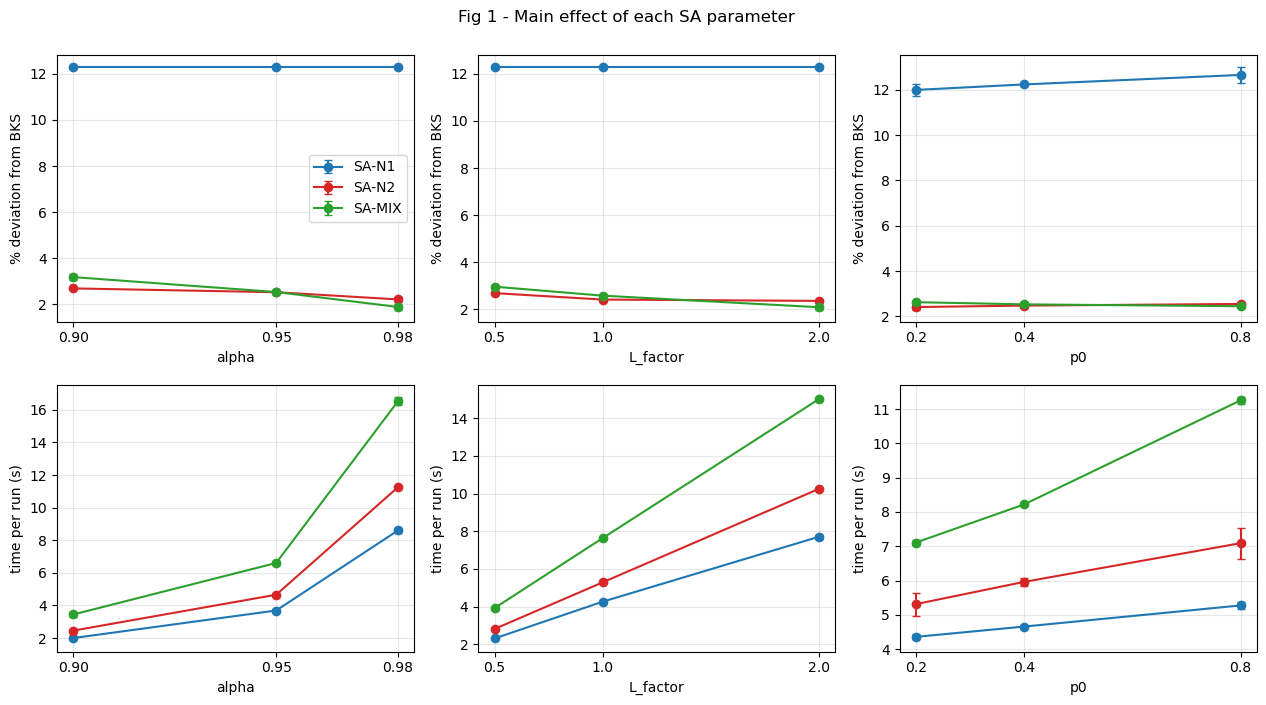

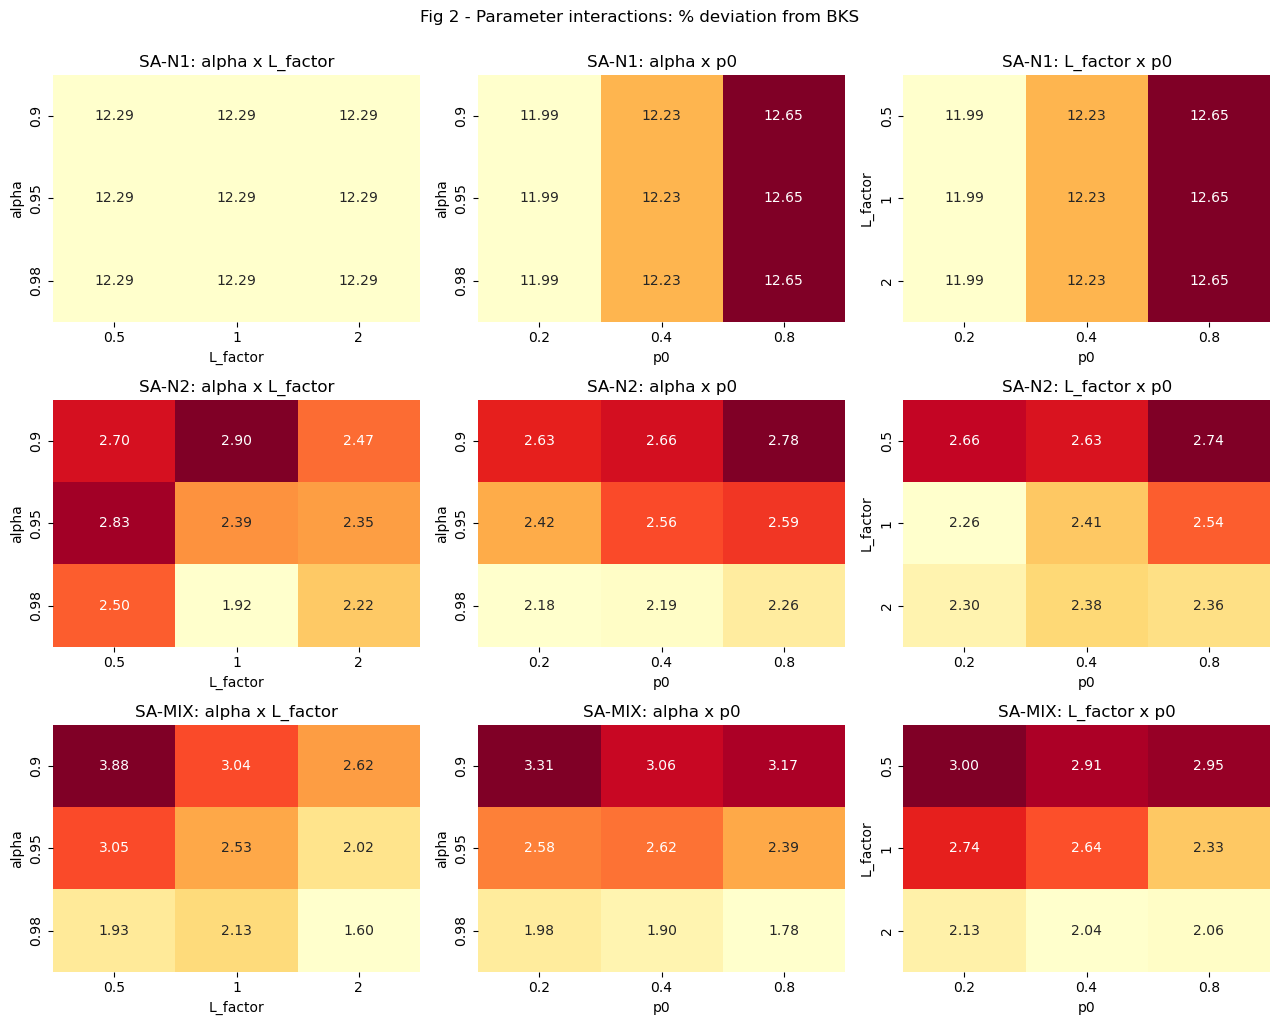

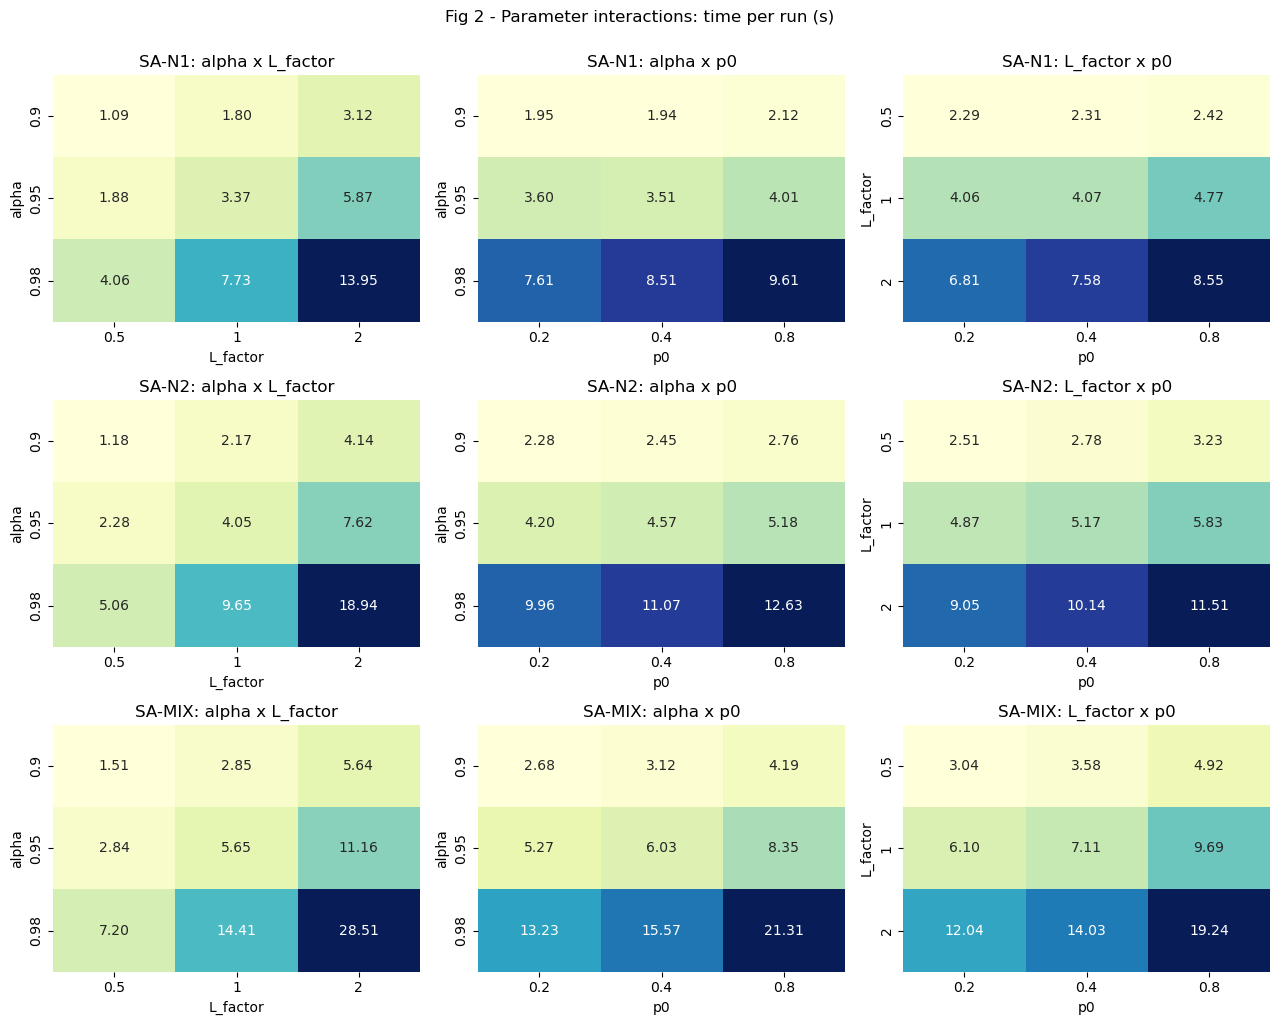

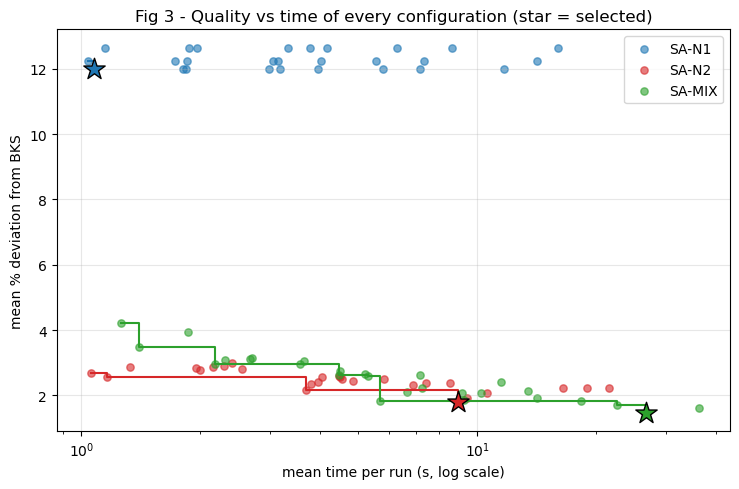

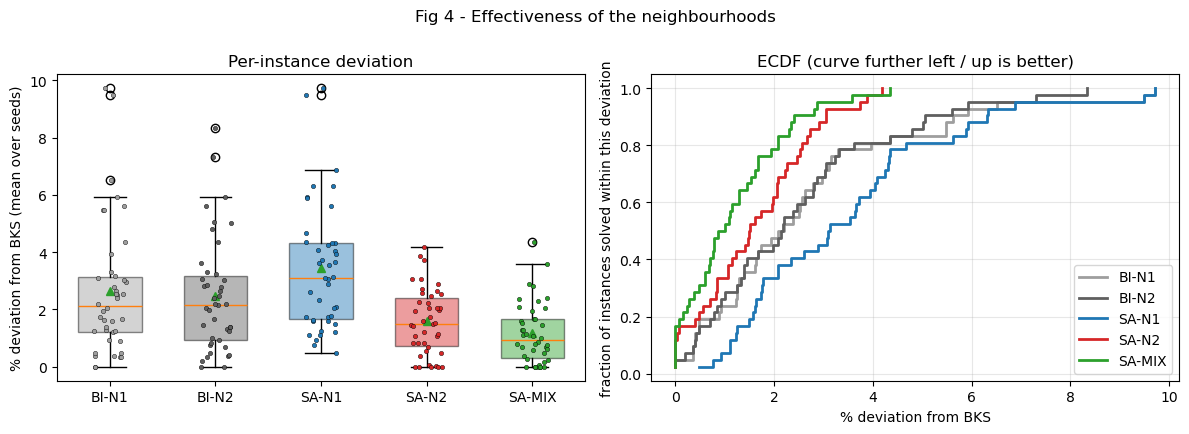

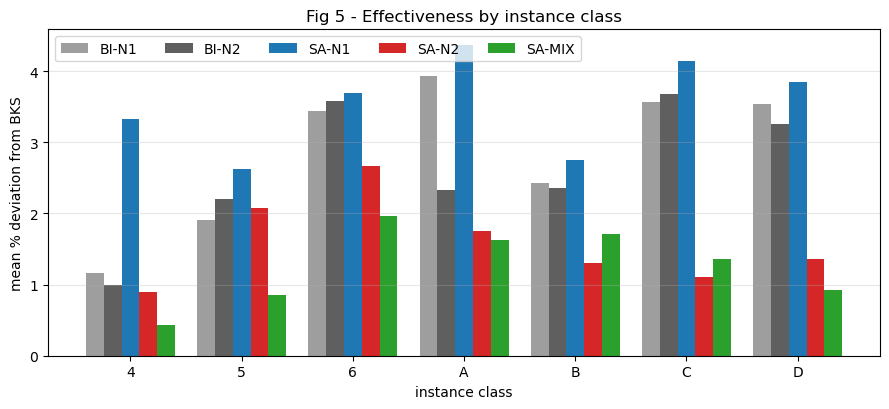

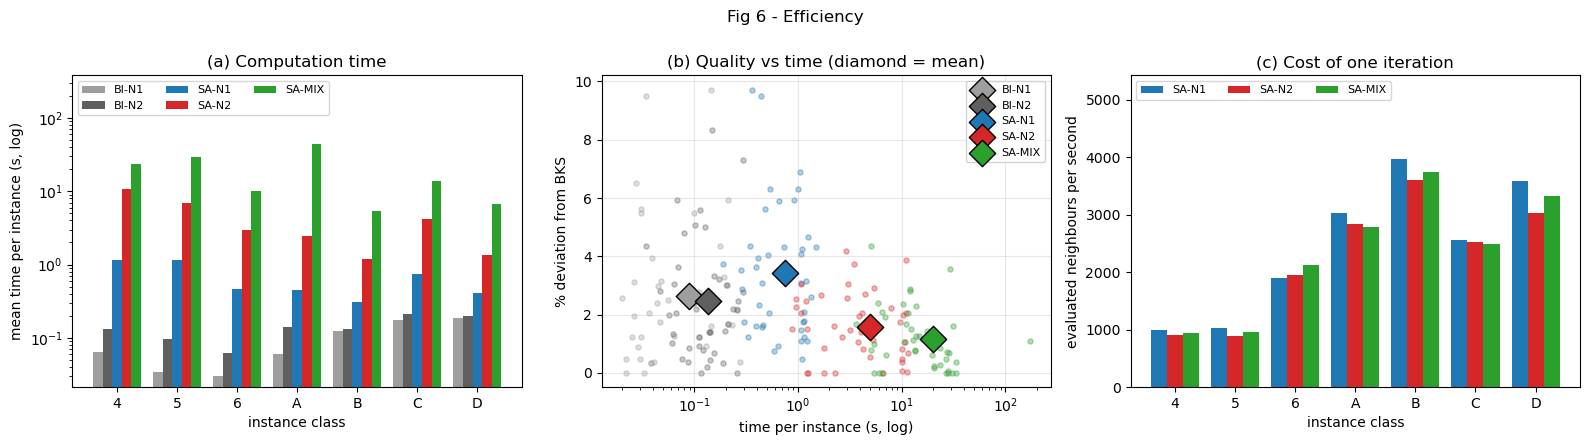

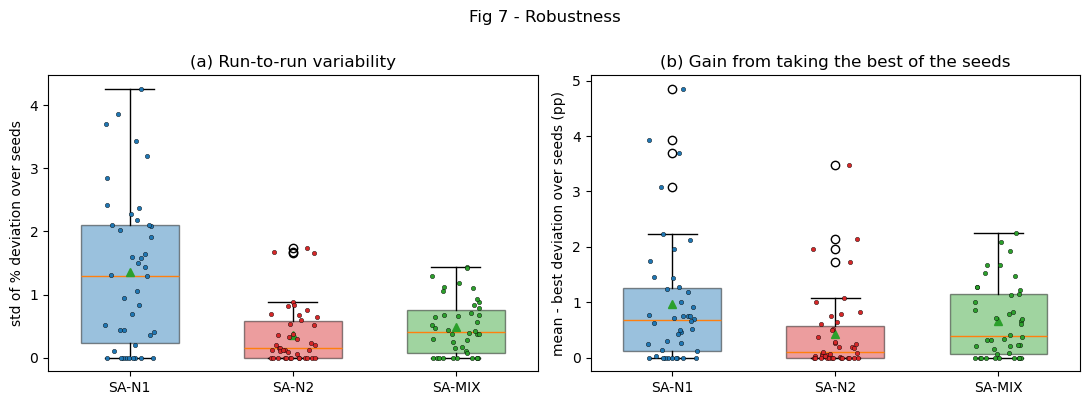

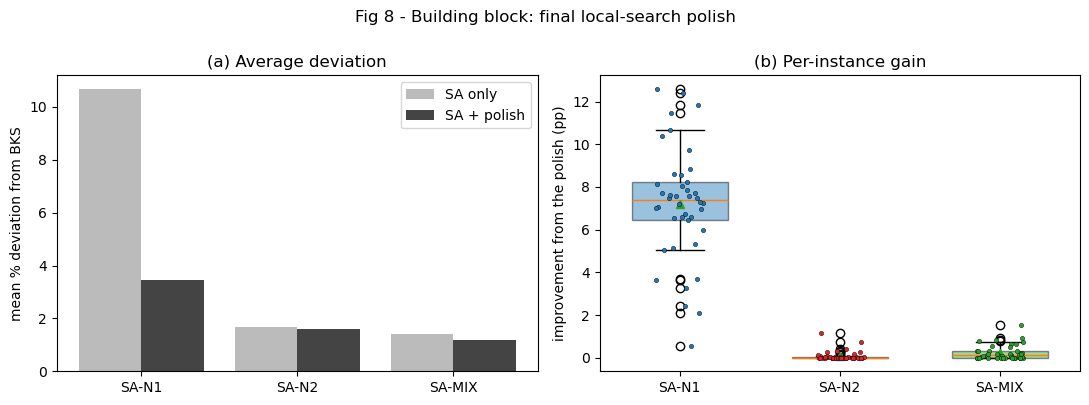

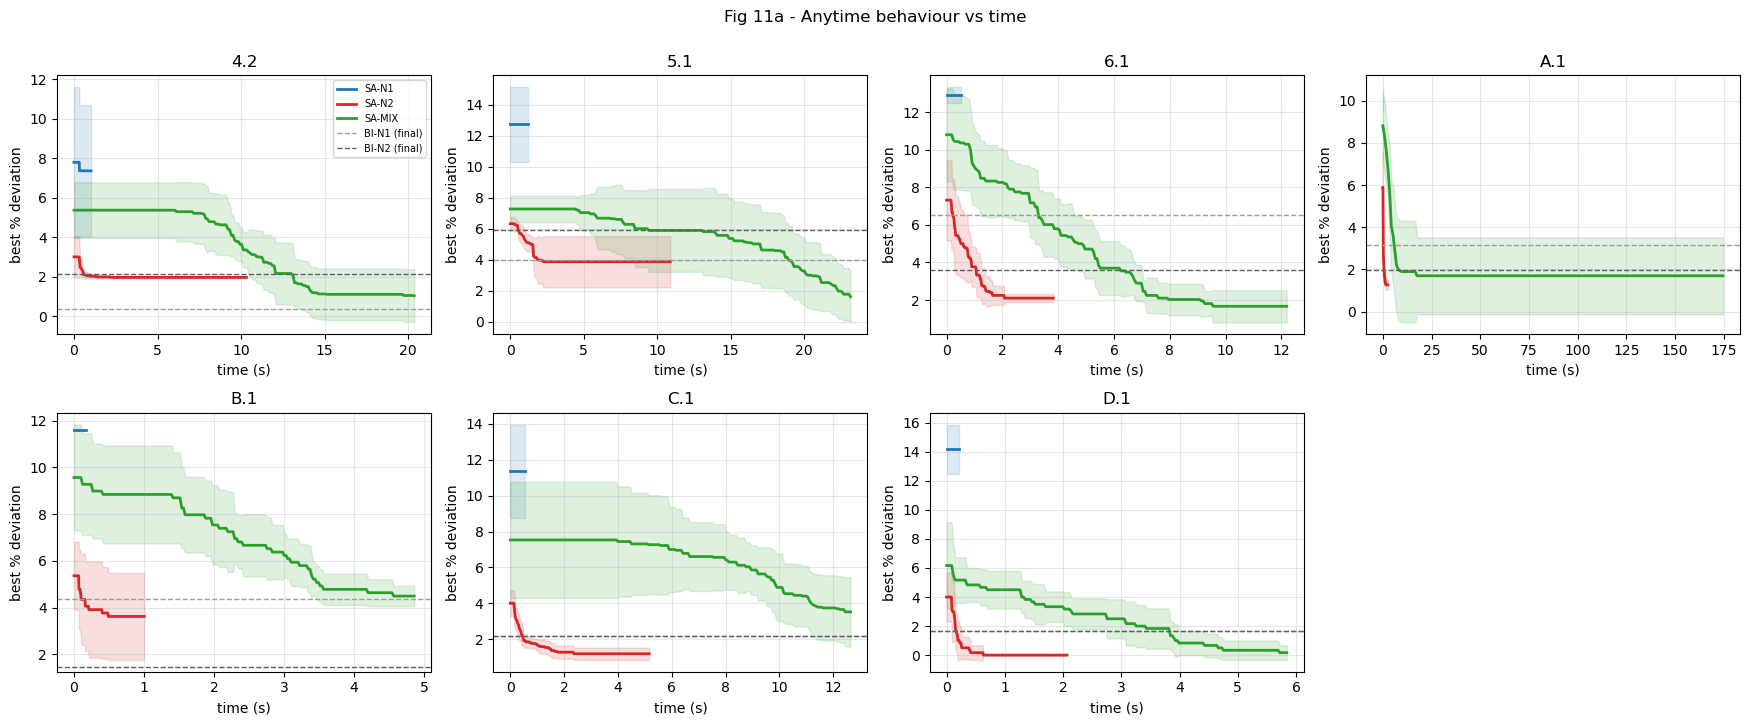

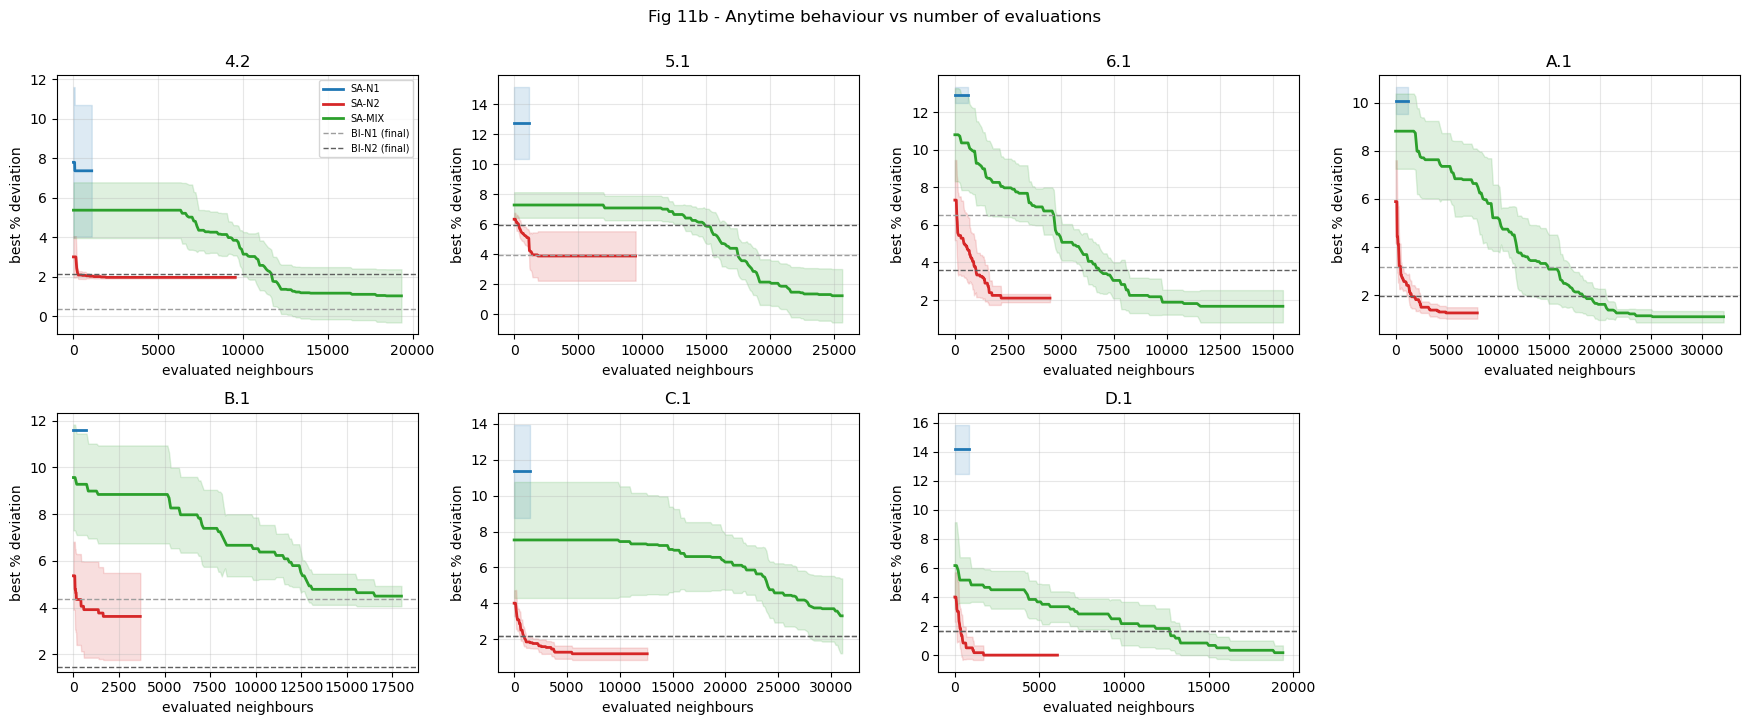

C:\Users\iscap\AppData\Local\Temp\ipykernel_26660\3456712755.py:378: RuntimeWarning: Mean of empty slice
  ax[0].plot(grid, np.nanmean(acc, axis=0), color=PALETTE[v], lw=2, label=v)
C:\Users\iscap\AppData\Local\Temp\ipykernel_26660\3456712755.py:379: RuntimeWarning: Mean of empty slice
  ax[1].plot(grid, np.nanmean(gap, axis=0), color=PALETTE[v], lw=2, label=v)


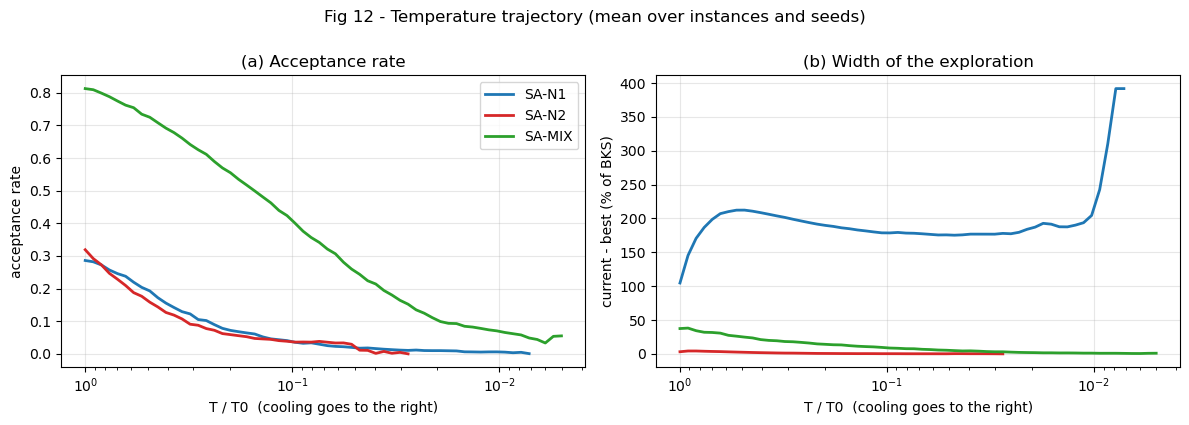

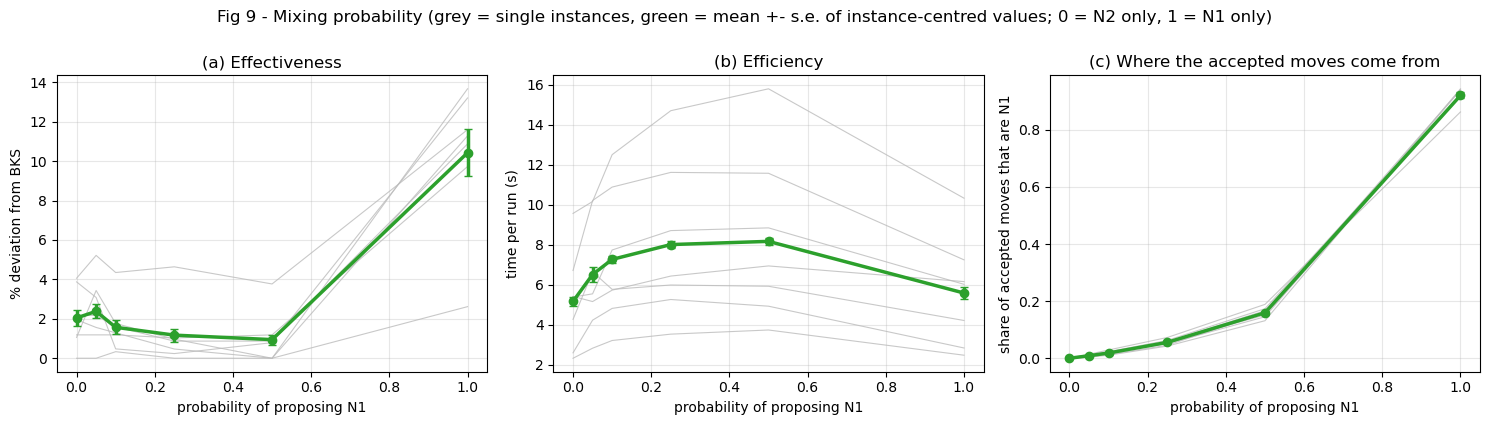

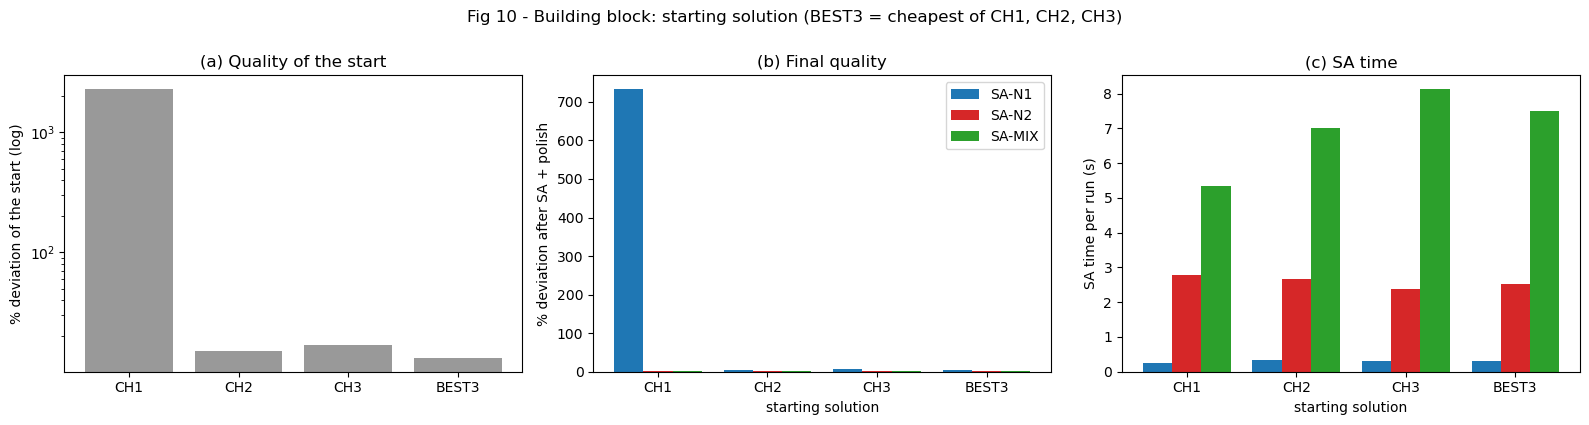

In [25]:
SAVE_FIGS = True              # figures are saved as PNG in ./figures_sa

# E1 - influence of the cooling parameters (from the tuning experiment)
if "df_tune" in globals() and len(df_tune):
    plot_main_effects(df_tune)
    plot_interactions(df_tune, "Pct_Dev", "fig2_interactions_dev")
    plot_interactions(df_tune, "Time_s", "fig2_interactions_time")
    plot_pareto(df_tune, best_params)

# E2, E5, E6, E7 - neighbourhoods, polish, search dynamics, robustness (from the final experiment)
if "df_sa" in globals() and len(df_sa):
    per_inst_all, _ = summarize_final(df_sa)
    plot_method_comparison(per_inst_all)
    plot_dev_by_class(per_inst_all)
    plot_efficiency(df_sa, per_inst_all)
    plot_robustness(per_inst_all)
    plot_polish_effect(per_inst_all)
    plot_anytime(sa_histories, BKS, df_sa, x="time")
    plot_anytime(sa_histories, BKS, df_sa, x="evals")
    plot_acceptance(sa_histories, BKS)

# E3 / E4 - building blocks
if "df_mix" in globals() and len(df_mix):
    plot_mix_sensitivity(df_mix)
if "df_start" in globals() and len(df_start):
    plot_start_ablation(df_start)